In [1]:
import sys
src_path = "/home/souvik/codes/foresee-main"
sys.path.append(src_path)
import matplotlib

import numpy as np
import os
from matplotlib import pyplot as plt
import math
import random
from skhep.math.vectors import LorentzVector, Vector3D
from scipy import interpolate
from matplotlib import gridspec
import os, inspect

In [2]:
from src_modified.foresee import Foresee, Utility, Model
foresee = Foresee()

energy = "100"
modelname="U1_llzplln_faser"
model = Model(modelname, path="./")

In [3]:
sys.path.insert(1, os.path.join(os.path.dirname(os.path.realpath(
                inspect.getfile(inspect.currentframe()))), "/home/souvik/codes/darkcast_chiral/"))
import darkcast 

In [4]:
model.add_production_2bodydecay(
    pid0 = "111",
    pid1 = "22",
    br = "2*0.99 * (coupling/0.303)**2 * pow(1.-pow(mass/self.masses('111'),2),3)",
#     br = "2*0.99 * (coupling)**2 * pow(1.-pow(mass/self.masses('111'),2),3)",
    generator = "EPOSLHC",
    energy = energy,
    nsample = 50,
)

model.add_production_2bodydecay(
    pid0 = "221",
    pid1 = "22",
    br = "2*0.25*0.39  * (coupling/0.303)**2 * pow(1.-pow(mass/self.masses('221'),2),3)",
#     br = "2*0.39 * (coupling)**2 * pow(1.-pow(mass/self.masses('221'),2),3)",
    generator = "EPOSLHC",
    energy = energy,
    nsample = 50, 
)

In [5]:
masses_brem = [ 
   0.01  ,  0.0126,  0.0158,  0.02  ,  0.0251,  0.0316,  0.0398,
   0.0501,  0.0631,  0.0794,  0.1   ,  0.1122,  0.1259,  0.1413,
   0.1585,  0.1778,  0.1995,  0.2239,  0.2512,  0.2818,  0.3162,
   0.3548,  0.3981,  0.4467,  0.5012,  0.5623,  0.6026,  0.631 ,
   0.6457,  0.6607,  0.6761,  0.6918,  0.7079,  0.7244,  0.7413,
   0.7586,  0.7762,  0.7943,  0.8128,  0.8318,  0.8511,  0.871 ,
   0.8913,  0.912 ,  0.9333,  0.955 ,  0.9772,  1.    ,  1.122 ,
   1.2589,  1.4125,  1.5849,  1.7783,  1.9953,  2.2387,  2.5119,
   2.8184,  3.1623,  3.9811,  5.0119,  6.3096,  7.9433, 10.    
]

model.add_production_direct(
    label = "Brem",
    energy = energy,
    condition = "1./0.3**2 * (p.pt<1)",
#     condition = "p.pt<1",
    coupling_ref=1,
    masses = masses_brem,
)

In [6]:
foresee.set_model(model=model)

In [7]:
path = "/home/souvik/codes/foresee-main/files/hadrons/100TeV/EPOSLHC/"
pids = ["111", "221"]
masses = {"111": 0.135, "221":0.547} 
names = {"111": "$\pi^0$", "221": "$\eta$"}
xlabels = {"111": r"$\theta_{\pi^0}$ [rad]", "221": r"$\theta_{\eta}$ [rad]"}
ylabels = {"111": r"p$_{\pi^0}$ [GeV]" , "221": r"p$_{\eta}$ [GeV]"}
for pid in pids:
    file = path+"EPOSLHC_100TeV_"+pid+".txt"
    with open(file, "r") as file:
        for line in file:
            data_list = [line.strip("\n") for line in file]
    data = data_list[3:]
    print(len(data))    

21000
21000


21000 21000


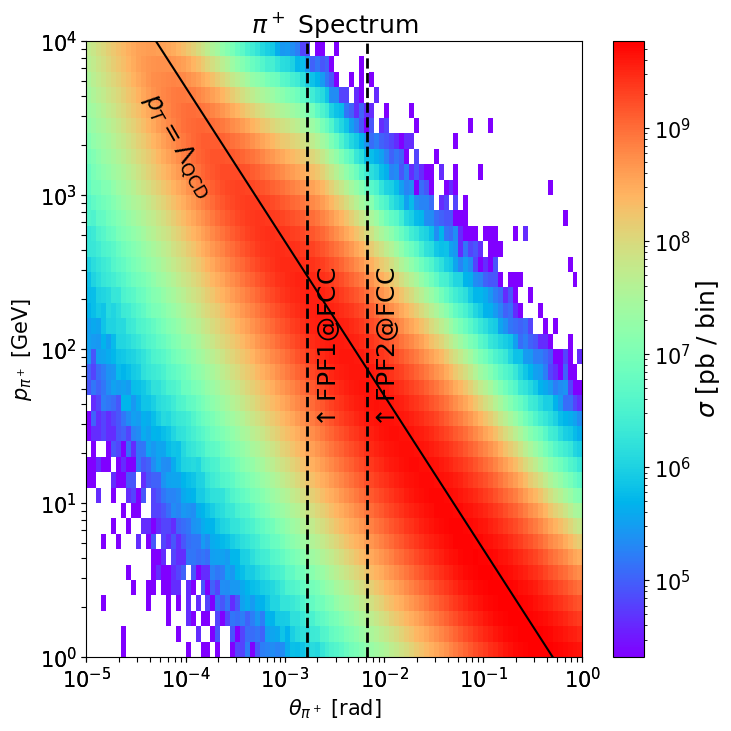

21000 21000


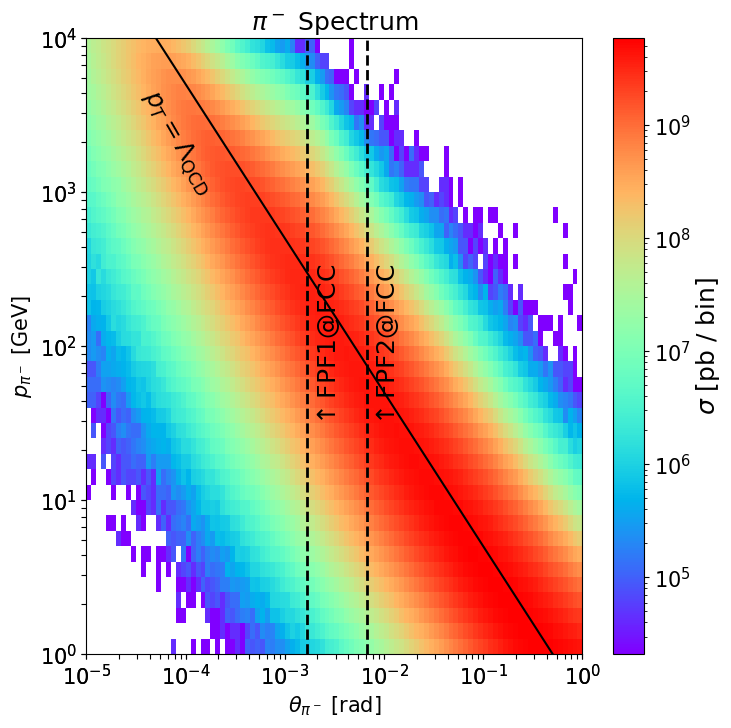

21000 21000


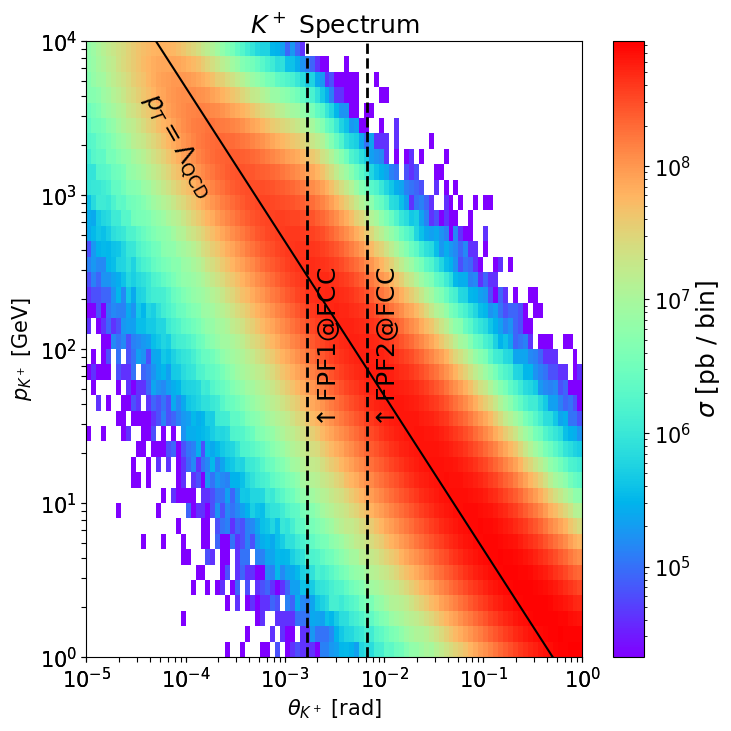

21000 21000


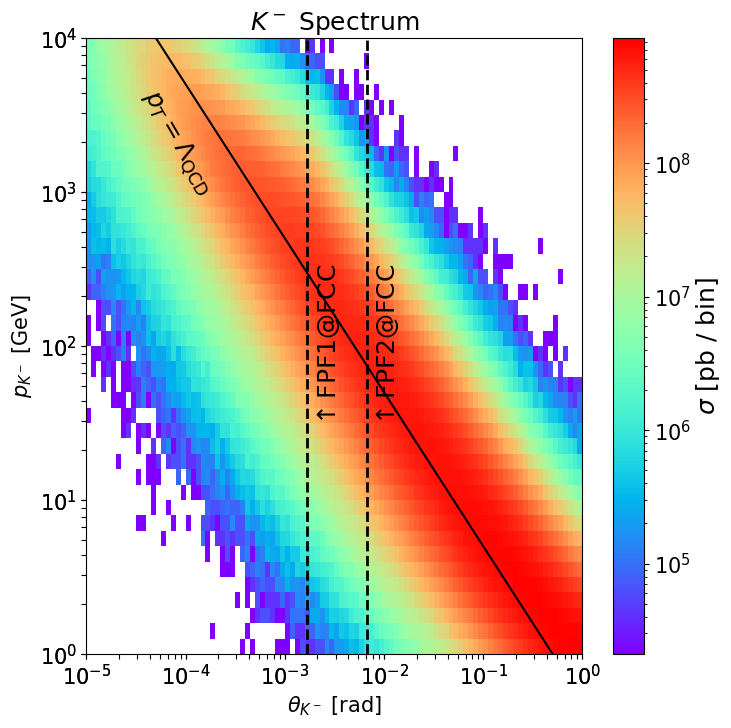

21000 21000


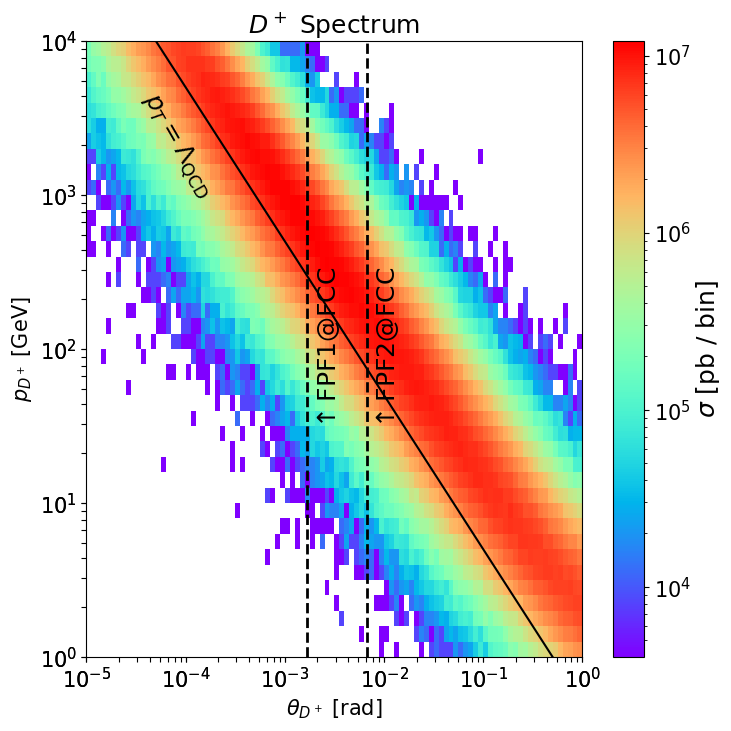

21000 21000


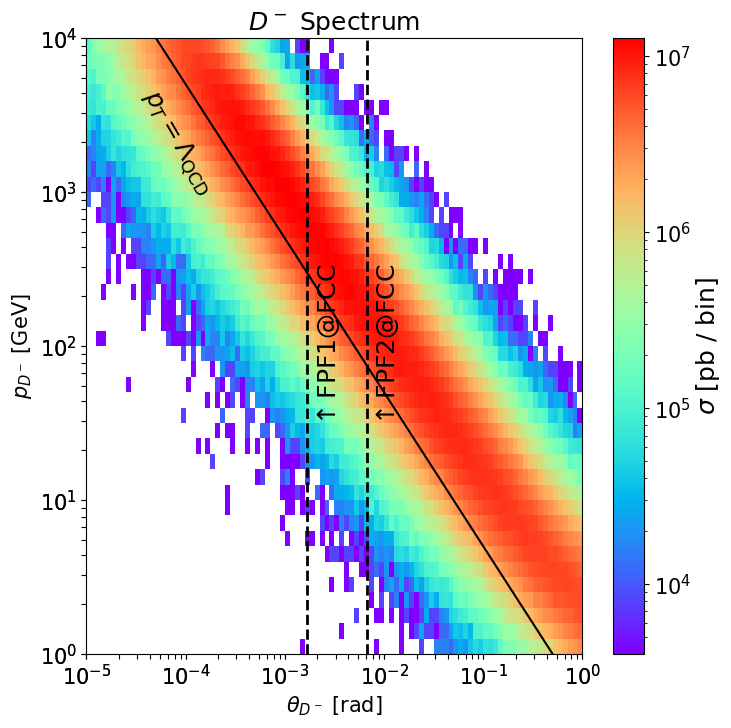

21000 21000


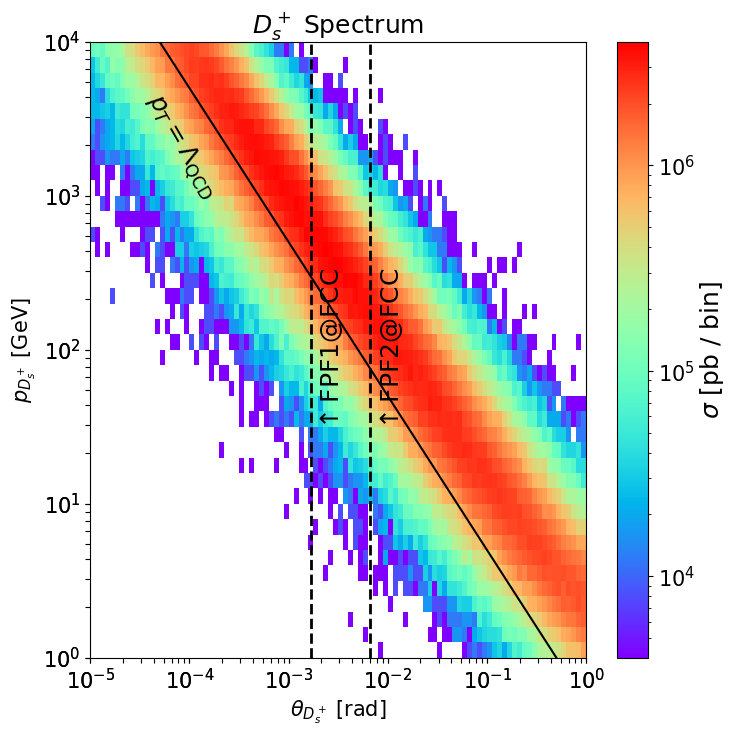

21000 21000


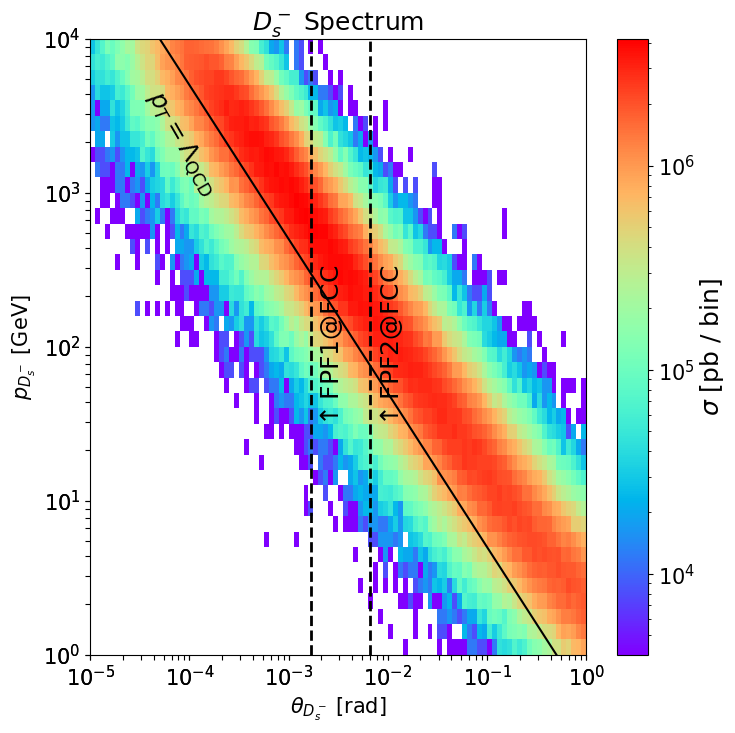

21000 21000


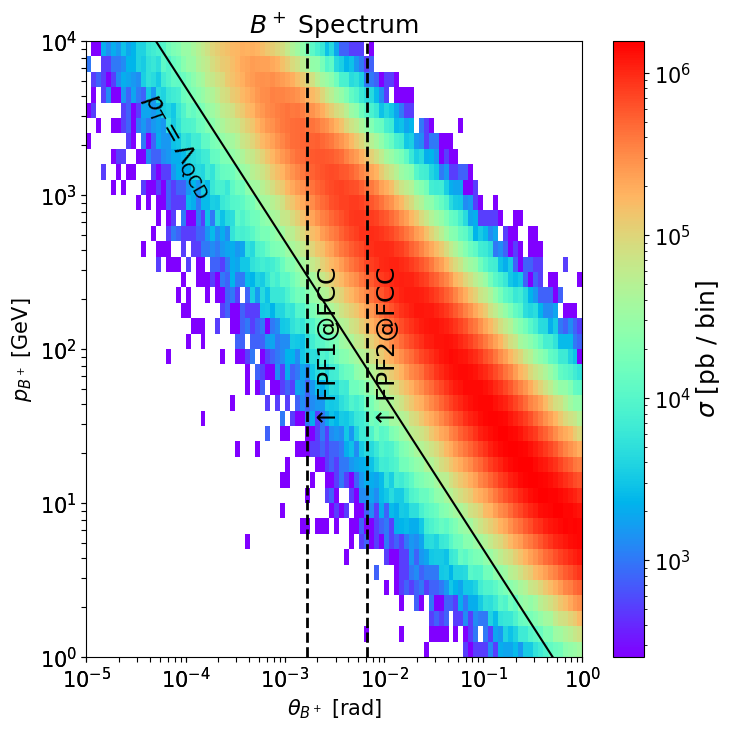

21000 21000


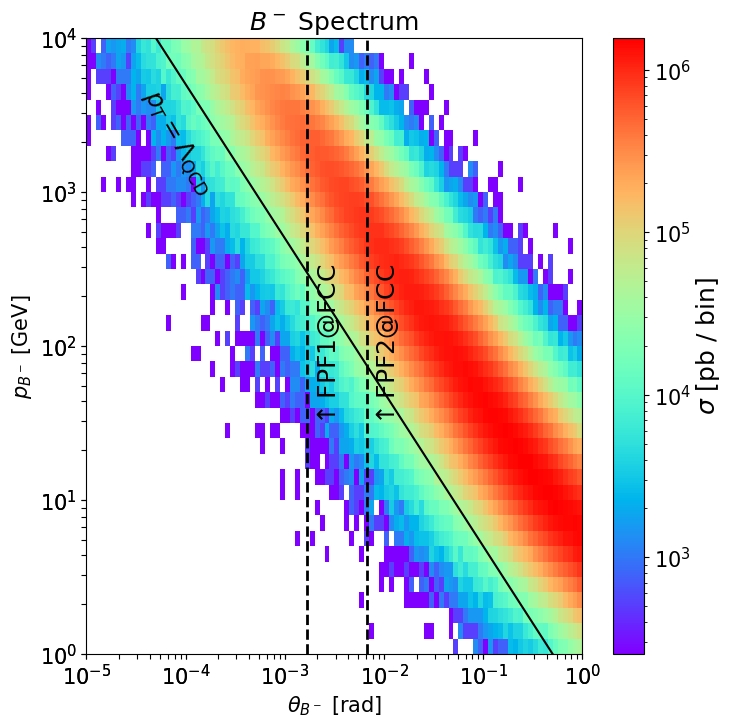

21000 21000


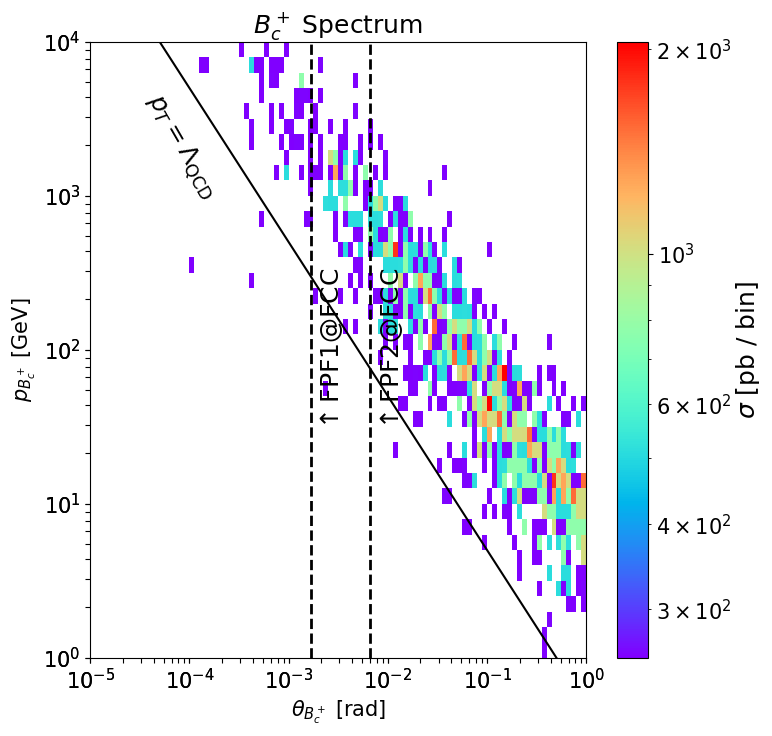

21000 21000


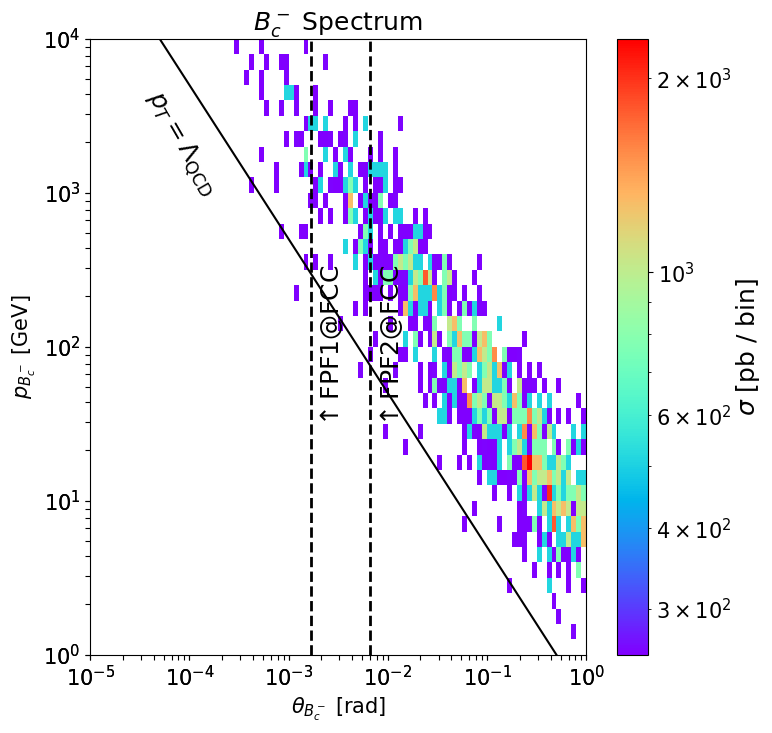

21000 21000


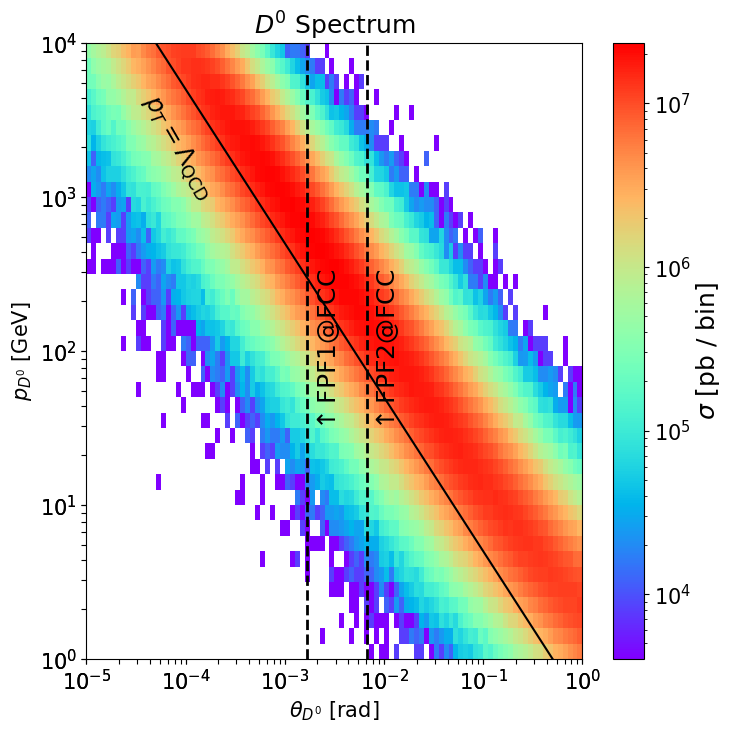

21000 21000


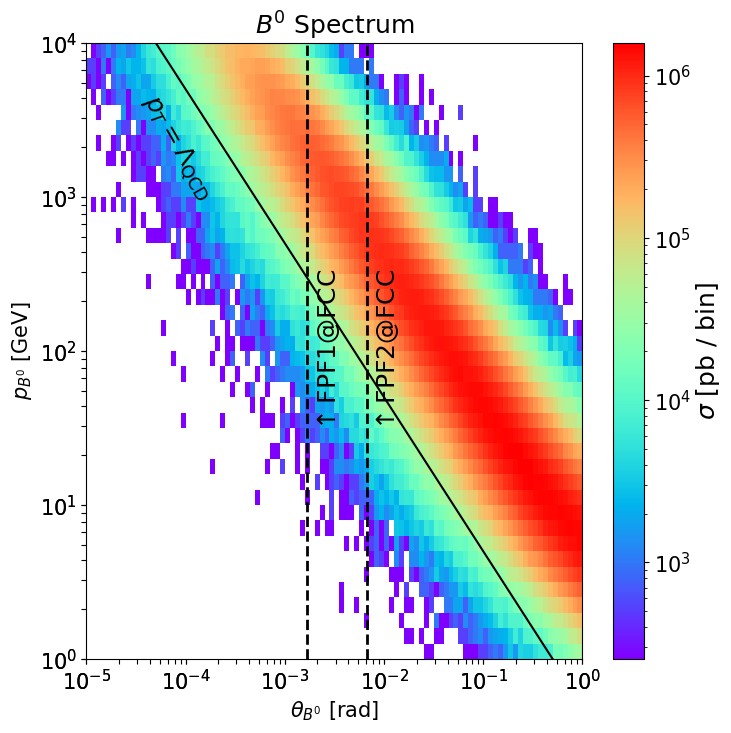

In [24]:
path = "/home/souvik/codes/foresee-main/files/hadrons/100TeV/"
pids = ["211", "-211", "321", "-321", "411", "-411", "431", "-431", "521", "-521", "541", "-541", "421", "511"]
generators = {"211":"EPOSLHC", "-211":"EPOSLHC", "321":"EPOSLHC", "-321":"EPOSLHC", "411": "Pythia8", "-411": "Pythia8", "421": "Pythia8", 
              "431": "Pythia8", "-431": "Pythia8", "521": "Pythia8", "-521": "Pythia8", "511": "Pythia8", "541": "Pythia8", "-541": "Pythia8"}

masses = {"211":0.139, "-211":0.139, "321":0.494, "-321":0.494, "411":0.187, "-411":0.187, "421":0.186, 
              "431": 0.197, "-431": 0.197, "521":0.528, "-521":0.528, "511":0.528, "541":0.627, "-541":0.627} 

names = {"211":"\pi^+", "-211":"\pi^-", "321":"K^+", "-321":"K^-", "411": "D^+", "-411": "D^-", "421": "D^0", 
              "431": "D_s^+", "-431": "D_s^-", "521": "B^+", "-521": "B^-", "511": "B^0", "541": "B_c^+", "-541": "B_c^-"}
for pid in pids:
    file = path+generators[pid]+"/"+ generators[pid] +"_100TeV_"+pid+".txt"
    data = np.genfromtxt(file)
    ps , ws = foresee.convert_list_to_momenta(file,masses[pid], filetype="txt",luminosity=3000, nsample=1,preselectioncut=None, 
                                      nocuts=False, mincount=0, extend_to_low_pt_scale=None)
    foresee.convert_to_hist_list(ps,ws,luminosity=1/1000, do_plot=True, filename=None, cmap="rainbow",
                         do_return=False, prange=[[-5, 0, 100],[0, 4, 40]], vmin=None, vmax=None)
    
    plt.gca()
    plt.axvline(x=np.log10(2.5/1500), color='black', linestyle='--', linewidth=2)
    plt.axvline(x=np.log10(10/1500), color='black', linestyle='--', linewidth=2)

    ts = [p.pt/p.p for p in ps]
    x = [np.log10(t) for t in ts]
    y = [np.log10(0.5)-i for i in x]
    print(len(ps), len(ws))
    plt.plot(x, y, color="black")
    plt.text(-2.7, 1.5, r"$\uparrow$FPF1@FCC", fontsize=18, rotation=90)
    plt.text(-2.1, 1.5, r"$\uparrow$FPF2@FCC", fontsize=18, rotation=90)
    
    plt.title(r"$"+names[pid]+"$ Spectrum")#, y=0.9, x=0.8)
    plt.text(-4.5, 3, r"$p_T=\Lambda_\text{QCD}$", fontsize=18, rotation=-60)
    
    plt.xlabel(r"$\theta_{"+names[pid]+"}$ [rad]")
    plt.ylabel(r"$p_{"+names[pid]+"}$ [GeV]")
    plt.savefig(r"/home/souvik/codes/FORESEE_fig/spectrum_100/"+pid+".png")
    plt.show()
    # foresee.get_spectrumplot(luminosity=3000, pid=pid, particle=r"$\Z'$--", generator="EPOSLHC", 
    #                      energy="14", prange=[[-6, 0, 120],[ 0, 5, 50]], vmin=0.5e12, vmax=0.5e16, mincount=0)

21000 21000


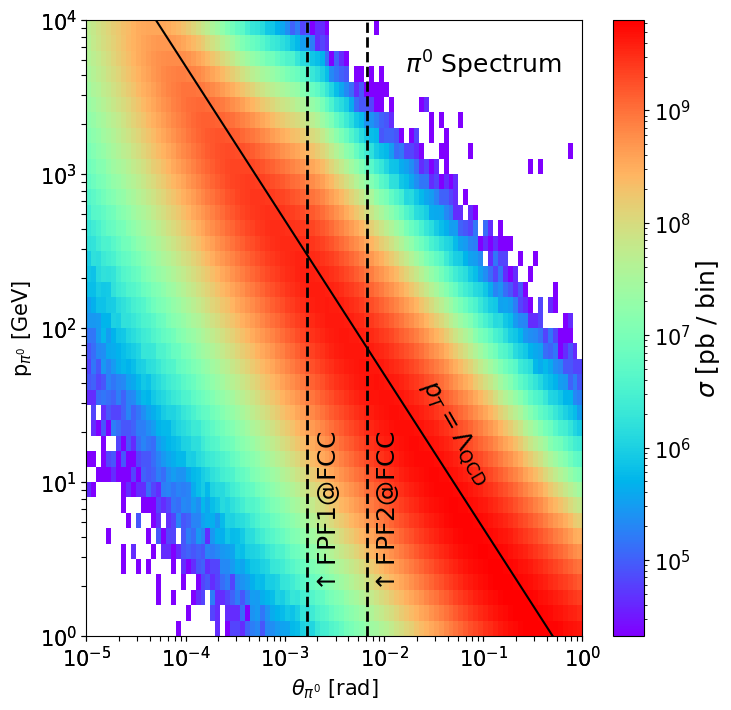

21000 21000


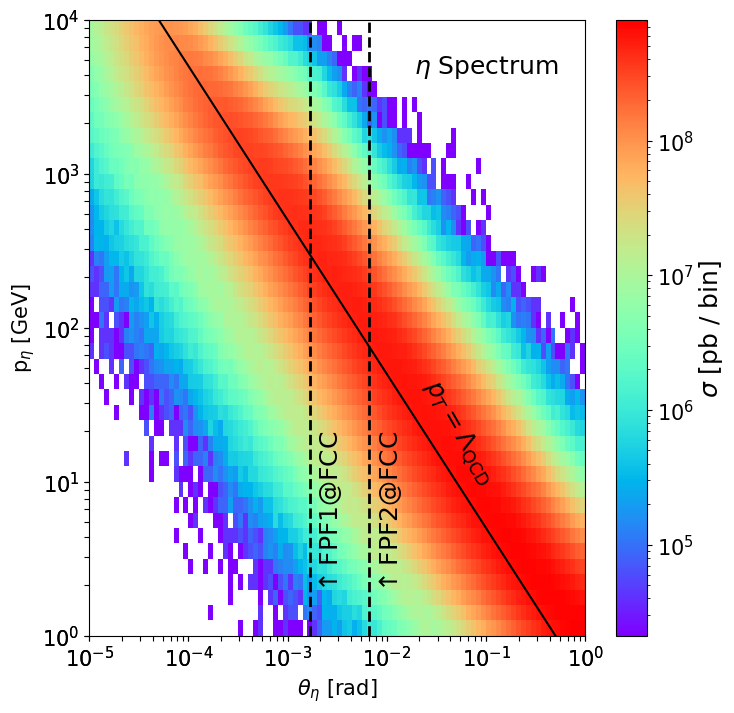

In [32]:
path = "/home/souvik/codes/foresee-main/files/hadrons/100TeV/EPOSLHC/"
pids = ["111", "221"]
masses = {"111": 0.135, "221":0.547} 
names = {"111": "$\pi^0$", "221": "$\eta$"}
xlabels = {"111": r"$\theta_{\pi^0}$ [rad]", "221": r"$\theta_{\eta}$ [rad]"}
ylabels = {"111": r"p$_{\pi^0}$ [GeV]" , "221": r"p$_{\eta}$ [GeV]"}
for pid in pids:
    file = path+"EPOSLHC_100TeV_"+pid+".txt"
    data = np.genfromtxt(file)
    ps , ws = foresee.convert_list_to_momenta(file,masses[pid], filetype="txt",luminosity=30000, nsample=1,preselectioncut=None, 
                                      nocuts=False, mincount=0, extend_to_low_pt_scale=None)
    foresee.convert_to_hist_list(ps,ws,luminosity=1/1000, do_plot=True, filename=None, cmap="rainbow",
                         do_return=False, prange=[[-5, 0, 100],[0, 4, 40]], vmin=None, vmax=None)
    
    plt.gca()
    plt.axvline(x=np.log10(2.5/1500), color='black', linestyle='--', linewidth=2)
    plt.axvline(x=np.log10(10/1500), color='black', linestyle='--', linewidth=2)

    ts = [p.pt/p.p for p in ps]
    x = [np.log10(t) for t in ts]
    y = [np.log10(0.5)-i for i in x]
    print(len(ps), len(ws))
    plt.plot(x, y, color="black")
    plt.text(-2.7, 0.3, r"$\uparrow$FPF1@FCC", fontsize=18, rotation=90)
    plt.text(-2.1, 0.3, r"$\uparrow$FPF2@FCC", fontsize=18, rotation=90)
    
    plt.title(r""+names[pid]+" Spectrum", y=0.9, x=0.8)
    plt.text(-1.7, 1, r"$p_T=\Lambda_\text{QCD}$", fontsize=18, rotation=-60)
    
    plt.xlabel(xlabels[pid])
    plt.ylabel(ylabels[pid])
    plt.savefig(r"/home/souvik/codes/FORESEE_fig/spectrum_100/"+pid+".png")
    plt.show()
    # foresee.get_spectrumplot(luminosity=3000, pid=pid, particle=r"$\Z'$--", generator="EPOSLHC", 
    #                      energy="14", prange=[[-6, 0, 120],[ 0, 5, 50]], vmin=0.5e12, vmax=0.5e16, mincount=0)

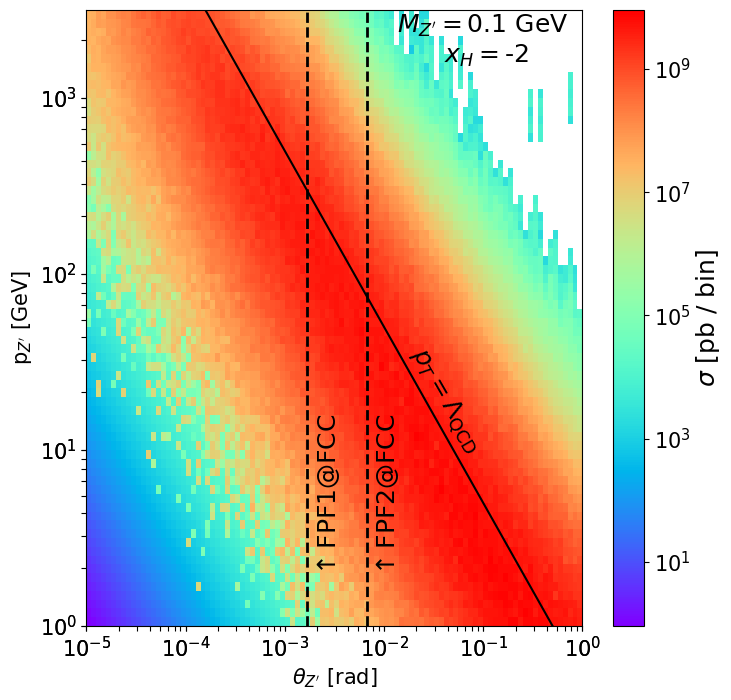

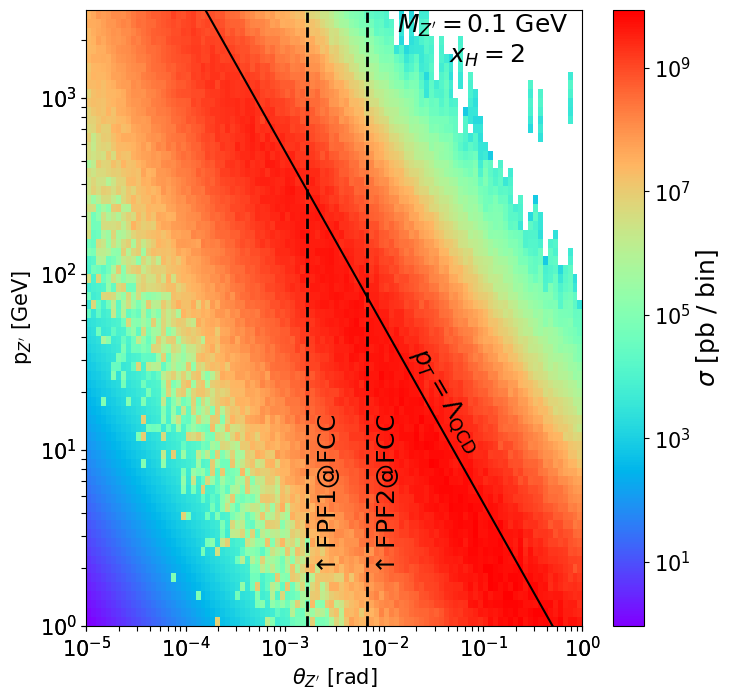

In [33]:
mass = 0.1
model1 = {-2: "U1_X_2n", 2: "U1_X_2p"}
xHs = [-2, 2]
for xH in xHs:
    foresee.get_llp_spectrum(mass=mass, coupling=1, luminosity=1/1000, mincount=0, cmap="rainbow",
                                do_plot=True, stat_cuts=None, save_file=False, prange=[[-5, 0, 100],[0, 3.5, 70]])
        # r = foresee.ratio(mass, model1[xH], "B-L_boson", key, 1/3, 1/3, 1/3)
        # for w,p in zip(ws, ps):
        #     Ps.append(p)
        #     Ws.append(w*r)
        
    # foresee.convert_to_hist_list(Ps,Ws,luminosity=1/1000, do_plot=True, filename=None, cmap="rainbow",
    #                      do_return=False, prange=[[-5, 0, 100],[0, 3.5, 70]], vmin=None, vmax=None)

    plt.title(r"$M_{Z'}=$"+str(mass)+" GeV \n $x_H=$"+str(xH), y=0.9, x=0.8)

    plt.gca()
    plt.axvline(x=np.log10(2.5/1500), color='black', linestyle='--', linewidth=2)
    plt.axvline(x=np.log10(10/1500), color='black', linestyle='--', linewidth=2)

    plt.text(-2.7, 0.3, r"$\uparrow$FPF1@FCC", fontsize=18, rotation=90)
    plt.text(-2.1, 0.3, r"$\uparrow$FPF2@FCC", fontsize=18, rotation=90)

    ts = 10**np.linspace(-5, 0, 100)
    x = [np.log10(t) for t in ts]
    y = [np.log10(0.5)-i for i in x]
    plt.plot(x, y, color="black")
    plt.text(-1.8, 1, r"$p_T=\Lambda_\text{QCD}$", fontsize=18, rotation=-60)
    plt.xlabel(r"$\theta_{Z^\prime}$ [rad]")
    plt.ylabel(r"p$_{Z^\prime}$ [GeV]")
    plt.savefig(r"/home/souvik/codes/FORESEE_fig/spectrum_100/Zp_"+str(xH)+".png")


In [8]:
def list_to_momenta(list_logth, list_logp, list_xs, mass, luminosity=3000, nsample=1):

    particles, weights = [], []
    for logth,logp,xs in zip(list_logth,list_logp, list_xs):

        # if nocuts==False and
        # if xs < mincount/(luminosity*1000): continue
        p  = 10.**logp
        th = 10.**logth
        pt = p * np.sin(th)

        for n in range(nsample):
            phi= random.uniform(-np.pi,np.pi)
            fth = 10**np.random.uniform(-0.025, 0.025, 1)[0]
            fp  = 10**np.random.uniform(-0.025, 0.025, 1)[0]

            th_sm=th*fth
            p_sm=p*fp

            en = np.sqrt(p_sm**2+mass**2)
            pz = p_sm*np.cos(th_sm)
            pt = p_sm*np.sin(th_sm)
            px = pt*np.cos(phi)
            py = pt*np.sin(phi)
            part=LorentzVector(px,py,pz,en)

            particles.append(part)
            weights.append(xs/float(nsample))

    return particles,weights

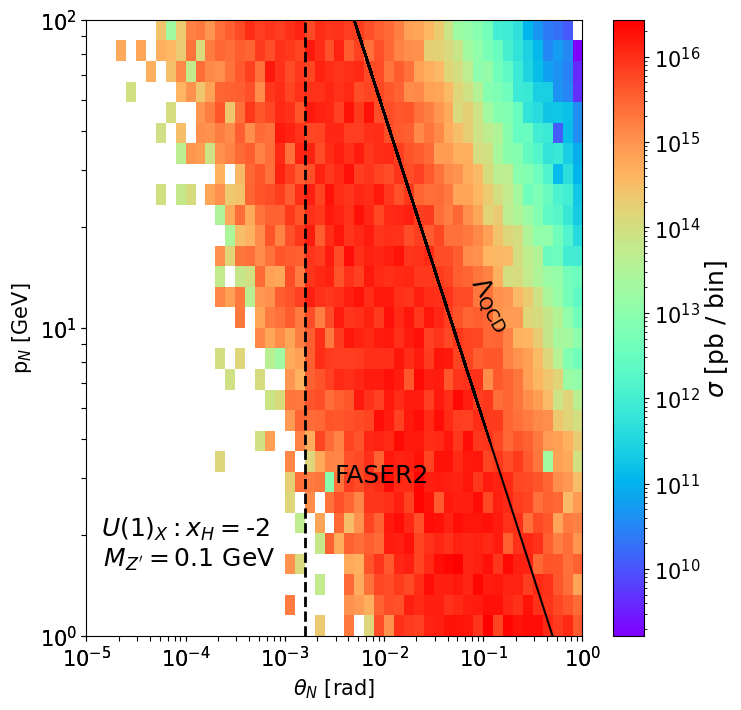

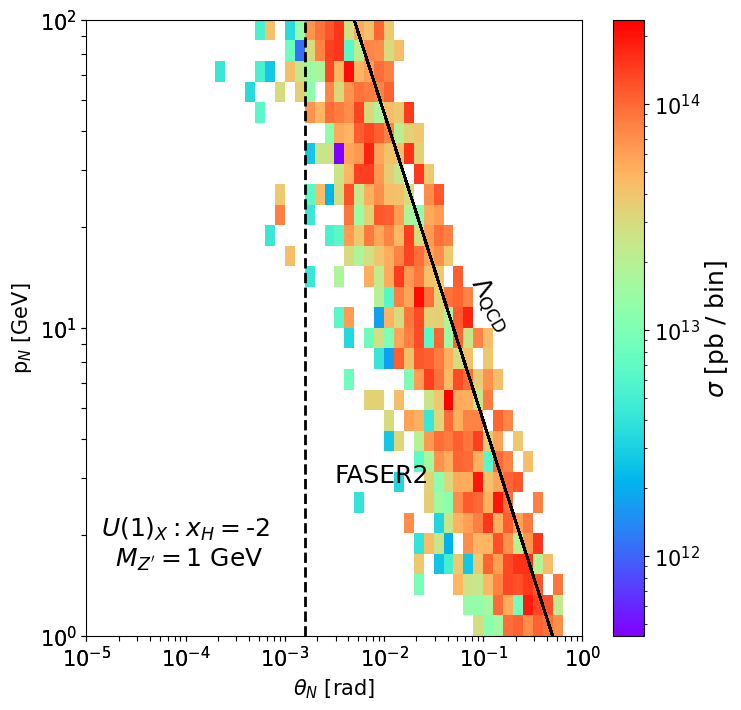

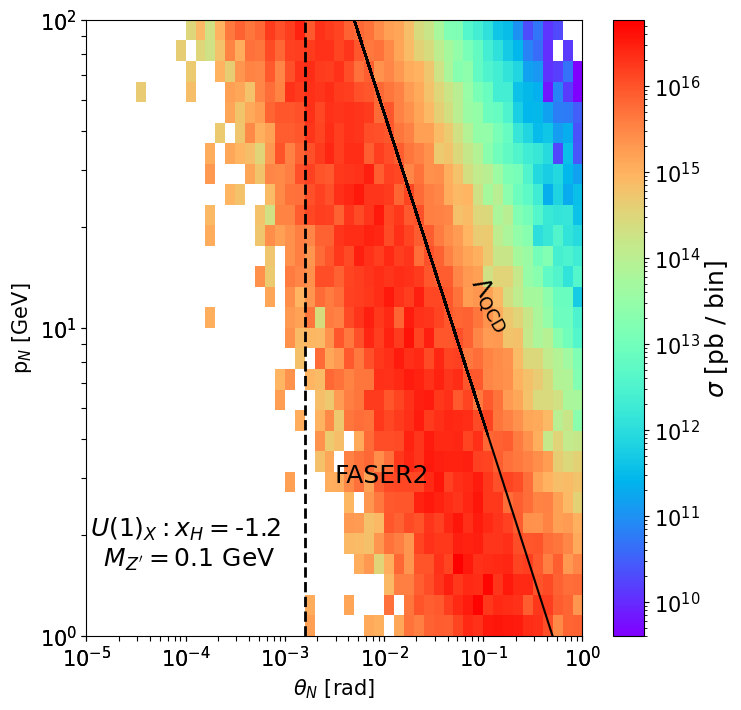

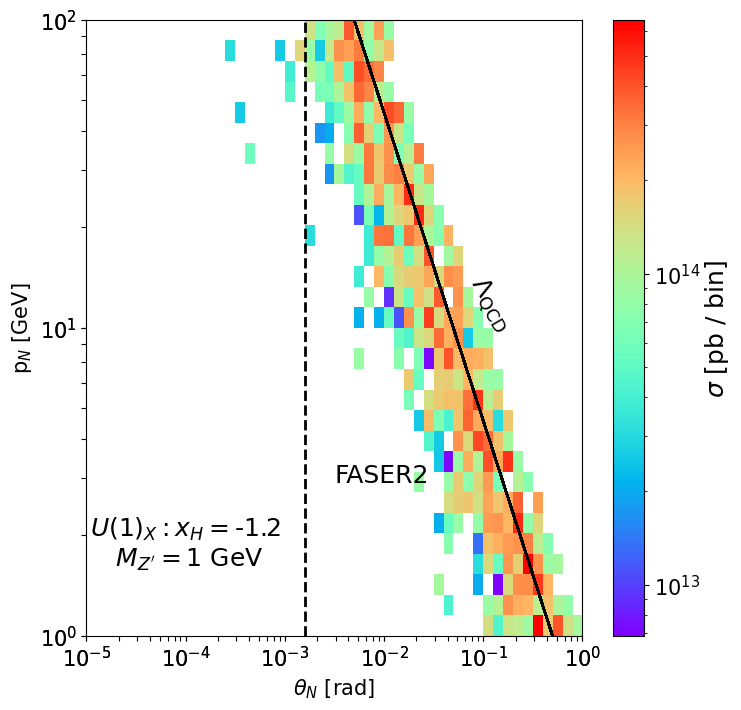

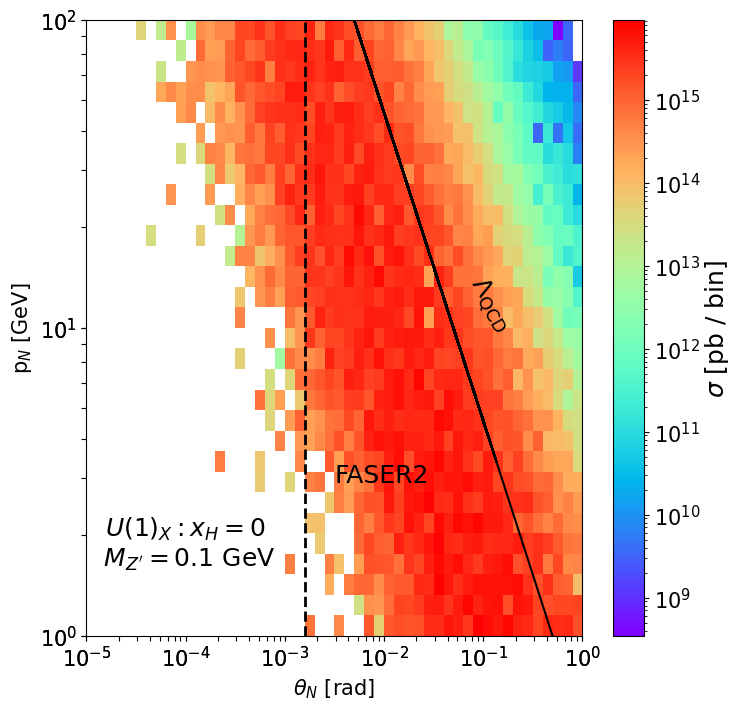

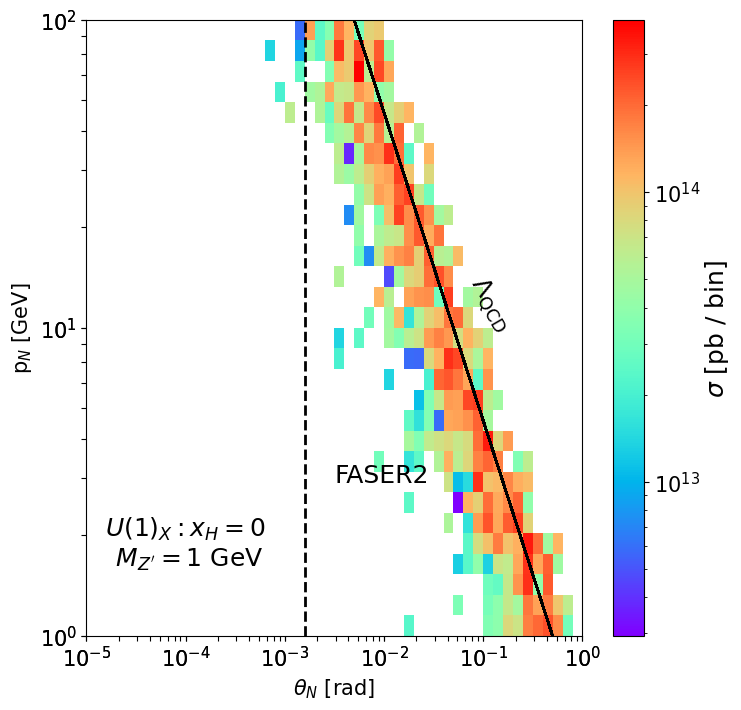

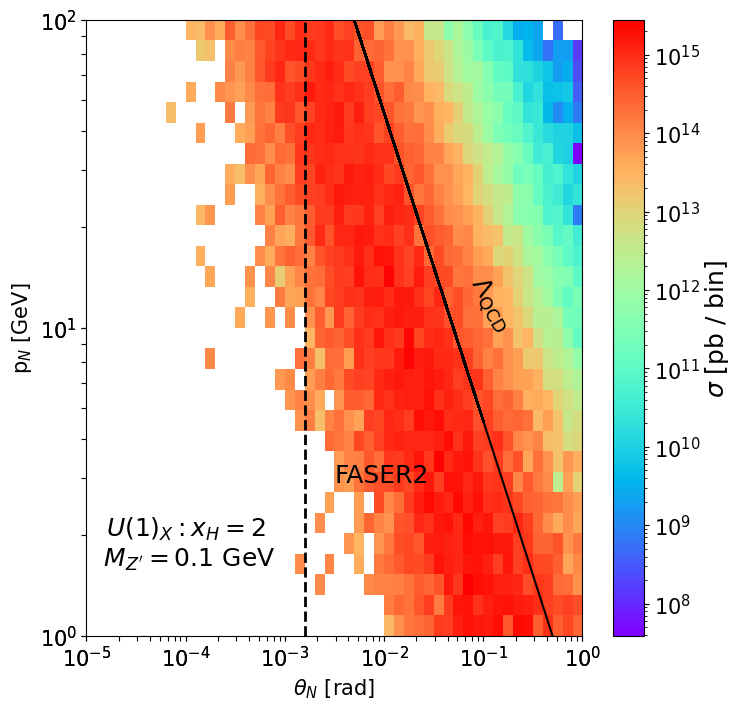

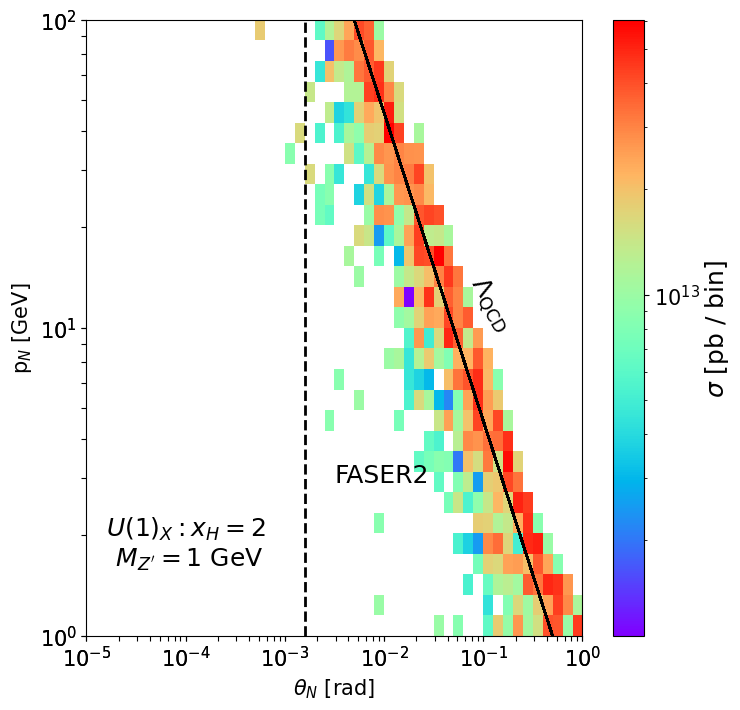

In [9]:
masses = [0.1, 1]
xHs = [-2, -1.2, 0, 2]
for xH in xHs:
    name = "U1_X"
    mN = 1/3
    modelD = darkcast.Model(name, m1 = 1/3, m2 = 1/3, m3 = 1000)
    for mass in masses:
        ts, ps, ws = foresee.get_llp_spectrum(mass=mass, coupling=1, luminosity=3000, mincount=0, cmap="rainbow", do_return=True,
                                    do_plot=False, stat_cuts=None, save_file=False, prange=[[-5, 0, 100],[0, 3.5, 70]])
        cp = random.uniform(-1,1)
        particles_llp, weights_llp = list_to_momenta(ts, ps, ws, mass, luminosity=3000, nsample=1)
        p1s = foresee.decay_in_restframe_2body(1, mass, mass*mN, mass*mN, 1)[0]
        pNs, wNs = [], []
        for p,w in zip(particles_llp,weights_llp):
            if w==0: continue
            for p1 in p1s:
                p1lab = p1.boost(-1.*p.boostvector)
                pNs.append(p1lab)
                wNs.append(w*(modelD.bfrac("Ne_Ne", mass, xH)+modelD.bfrac("Nmu_Nmu", mass, xH))/2)
                p2lab = p - p1lab
                pNs.append(p2lab)
                wNs.append(w*(modelD.bfrac("Ne_Ne", mass, xH)+modelD.bfrac("Nmu_Nmu", mass, xH))/2)
        
        foresee.convert_to_hist_list(pNs,wNs,luminosity=3000, do_plot=True, filename=None, cmap="rainbow",
                             do_return=False, prange=[[-5, 0, 50],[0, 2, 30]], vmin=None, vmax=None)
        plt.gca()
        plt.axvline(x=np.log10(1/630), color='black', linestyle='--', linewidth=2)

        ts = [p.pt/p.p for p in pNs]
        x = [np.log10(t) for t in ts]
        y = [np.log10(0.5)-i for i in x]
        plt.plot(x, y, color="black")
        plt.text(-2.5, 0.5, "FASER2", fontsize=18)
        plt.text(-1.2, 1, r"$\Lambda_\text{QCD}$", fontsize=18, rotation=-60)

        
        plt.xlabel(r"$\theta_{N}$ [rad]")
        plt.ylabel(r"p$_{N}$ [GeV]")
        
        plt.title(r"$U(1)_X: x_H=$"+str(xH)+"\n $M_{Z'}=$"+str(mass)+" GeV", y = 0.1, x = 0.2)
        plt.savefig(r"/home/souvik/codes/FORESEE_fig/spectrum/U1X_xH_"+str(xH)+"_"+str(mass)+".png")

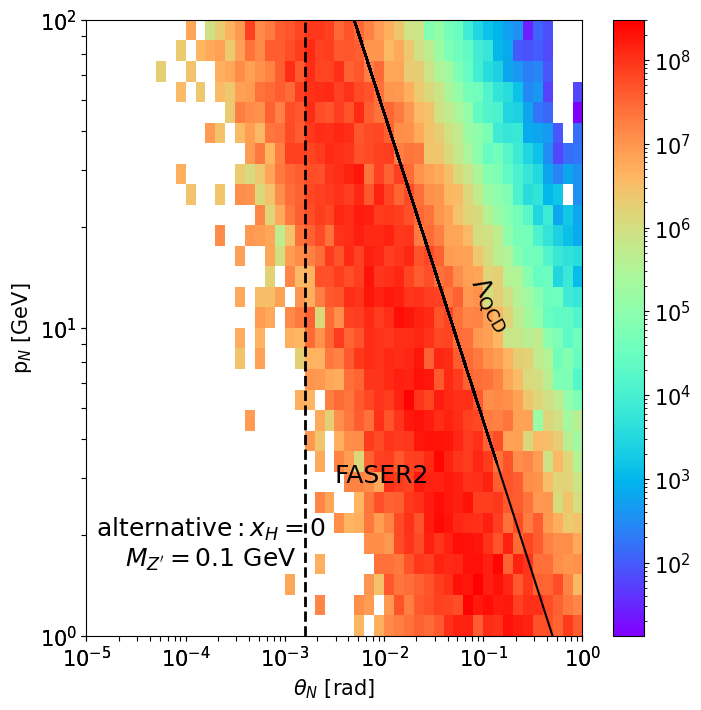

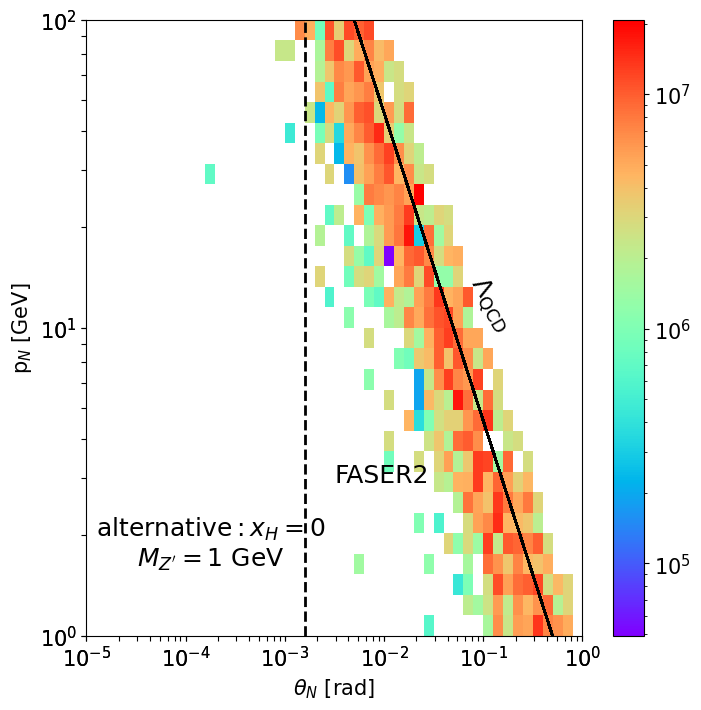

In [10]:
masses = [0.1, 1]
xHs = [0]#[-2, -1.2, 0, 2]
for xH in xHs:
    name = "U1_X_phi4"
    mN = 1/3
    modelD = darkcast.Model(name, m1 = 1/3, m2 = 1/3, m3 = 1000)
    for mass in masses:
        ts, ps, ws = foresee.get_llp_spectrum(mass=mass, coupling=1, luminosity=3000, mincount=0, cmap="rainbow", do_return=True,
                                    do_plot=False, stat_cuts=None, save_file=False, prange=[[-5, 0, 100],[0, 3.5, 70]])
        cp = random.uniform(-1,1)
        particles_llp, weights_llp = list_to_momenta(ts, ps, ws, mass, luminosity=3000, nsample=1)
        p1s = foresee.decay_in_restframe_2body(1, mass, mass*mN, mass*mN, 1)[0]
        pNs, wNs = [], []
        for p,w in zip(particles_llp,weights_llp):
            if w==0: continue
            for p1 in p1s:
                p1lab = p1.boost(-1.*p.boostvector)
                pNs.append(p1lab)
                wNs.append(w*(modelD.bfrac("Ne_Ne", mass, xH)+modelD.bfrac("Nmu_Nmu", mass, xH))/2*1e-8)
                p2lab = p - p1lab
                pNs.append(p2lab)
                wNs.append(w*(modelD.bfrac("Ne_Ne", mass, xH)+modelD.bfrac("Nmu_Nmu", mass, xH))/2*1e-8)
        
        foresee.convert_to_hist_list(pNs,wNs,luminosity=3000, do_plot=True, filename=None, cmap="rainbow",
                             do_return=False, prange=[[-5, 0, 50],[0, 2, 30]], vmin=None, vmax=None)
        plt.gca()
        plt.axvline(x=np.log10(1/630), color='black', linestyle='--', linewidth=2)

        ts = [p.pt/p.p for p in pNs]
        x = [np.log10(t) for t in ts]
        y = [np.log10(0.5)-i for i in x]
        plt.plot(x, y, color="black")
        plt.text(-2.5, 0.5, "FASER2", fontsize=18)
        plt.text(-1.2, 1, r"$\Lambda_\text{QCD}$", fontsize=18, rotation=-60)

        
        plt.xlabel(r"$\theta_{N}$ [rad]")
        plt.ylabel(r"p$_{N}$ [GeV]")
        
        plt.title(r"alternative$: x_H=$"+str(xH)+"\n$M_{Z'}=$"+str(mass)+" GeV", y = 0.1, x = 0.25)
        plt.savefig(r"/home/souvik/codes/FORESEE_fig/spectrum/454_xH_"+str(xH)+"_"+str(mass)+".png")

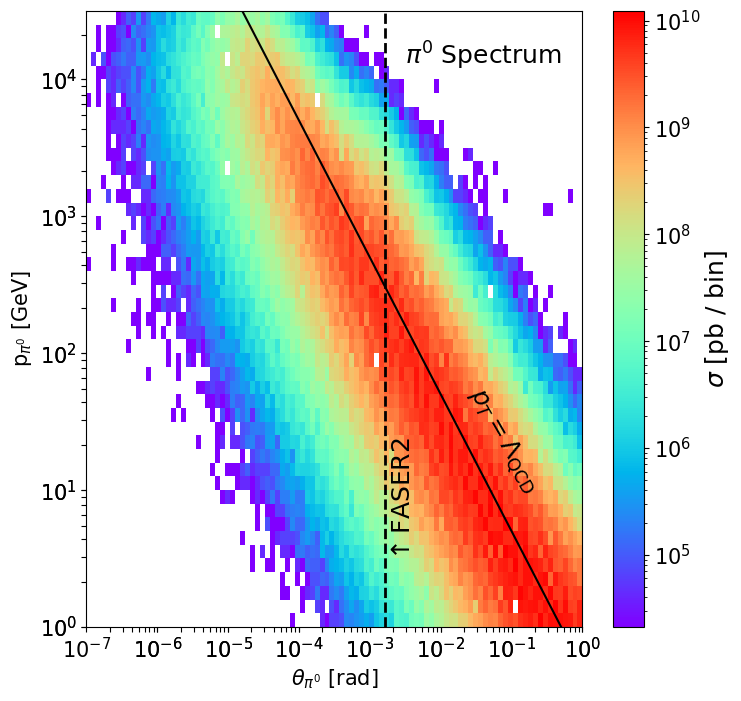

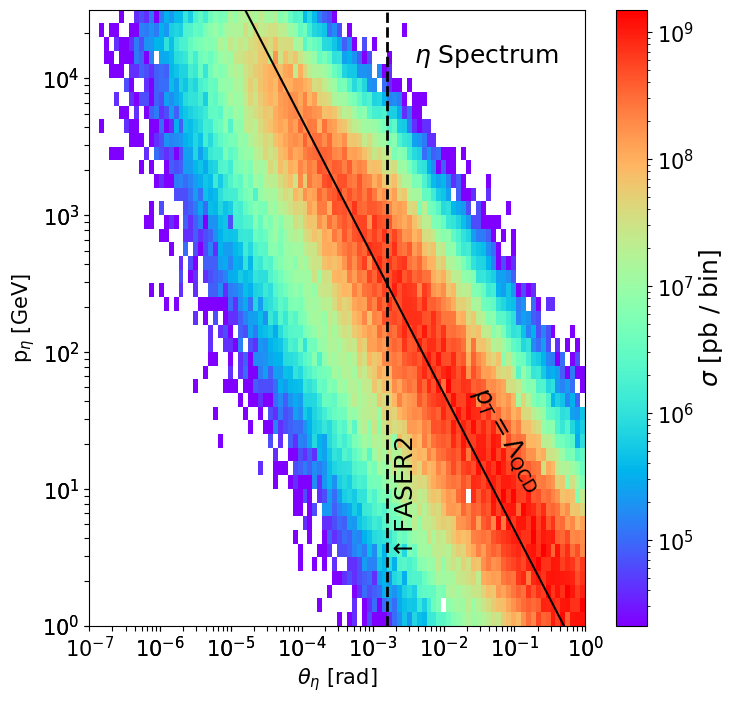

In [7]:
path = "/home/souvik/codes/foresee-main/files/hadrons/100TeV/EPOSLHC/"
pids = ["111", "221"]
masses = {"111": 0.135, "221":0.547} 
names = {"111": "$\pi^0$", "221": "$\eta$"}
xlabels = {"111": r"$\theta_{\pi^0}$ [rad]", "221": r"$\theta_{\eta}$ [rad]"}
ylabels = {"111": r"p$_{\pi^0}$ [GeV]" , "221": r"p$_{\eta}$ [GeV]"}
for pid in pids:
    file = path+"EPOSLHC_100TeV_"+pid+".txt"
    data = np.genfromtxt(file)
    ps , ws = foresee.convert_list_to_momenta(file,masses[pid], filetype="txt",luminosity=3000, nsample=1,preselectioncut=None, 
                                      nocuts=False, mincount=0, extend_to_low_pt_scale=None)
    foresee.convert_to_hist_list(ps,ws,luminosity=1/1000, do_plot=True, filename=None, cmap="rainbow",
                         do_return=False, prange=[[-7, 0, 100],[0, 4.5, 45]], vmin=None, vmax=None)
    
    plt.gca()
    plt.axvline(x=np.log10(2.5/1550), color='black', linestyle='--', linewidth=2)

    ts = [p.pt/p.p for p in ps]
    x = [np.log10(t) for t in ts]
    y = [np.log10(0.5)-i for i in x]
    plt.plot(x, y, color="black")
    plt.text(-2.7, 0.5, r"$\uparrow$FASER2", fontsize=18, rotation=90)
    
    plt.title(r""+names[pid]+" Spectrum", y=0.9, x=0.8)
    plt.text(-1.7, 1, r"$p_T=\Lambda_\text{QCD}$", fontsize=18, rotation=-60)
    
    plt.xlabel(xlabels[pid])
    plt.ylabel(ylabels[pid])
    plt.savefig(r"/home/souvik/codes/FORESEE_fig/spectrum/100TeV_"+pid+".png")
    plt.show()
    # foresee.get_spectrumplot(luminosity=3000, pid=pid, particle=r"$\Z'$--", generator="EPOSLHC", 
    #                      energy="14", prange=[[-6, 0, 120],[ 0, 5, 50]], vmin=0.5e12, vmax=0.5e16, mincount=0)

In [7]:
mesons = {r"$\gamma$" :  22, 
        r"$\pi^0$"   :  111, 
         r"$\rho^0$"  :  113, 
          r"$K^0_L$" :   130, 
          r"$\pi^+$" :   211,  
          r"$\eta$" :   221,  
         r"$\omega$"  :   223, 
          r"$K^0_S$":   310,  
           r"$K^*(892)$":   313,  
           r"$K^+$":   321,  
           # r"$K^{*+}(892)$":   323,  
           r"$\eta'$":   331,  
           r"$h_1$":   333,  
           r"$n$":   2112,  
           r"$p$":   2212,  
           r"$\Lambda$":   3122,  
           r"$\pi^-$" :   -211,   
           r"$\bar{K^*}(892)$":   -313,  
           r"$K^-$":   -321,  
           # r"$K^{*-}(892)$":   -323,  
           r"$\bar{n}$":   -2112,  
           r"$\bar{p}$":   -2212,  
           r"$\bar{\Lambda}$":   -3122,  }

In [8]:
def masses(pid,mass=0):
    if   pid in ["2112","-2112"]: return 0.938
    elif pid in ["2212","-2212"]: return 0.938
    elif pid in ["211" ,"-211" ]: return 0.13957
    elif pid in ["321" ,"-321" ]: return 0.49368
    elif pid in ["310" ,"130"  ]: return 0.49761
    elif pid in ["111"         ]: return 0.135
    elif pid in ["221"         ]: return 0.547
    elif pid in ["331"         ]: return 0.957
    elif pid in ["3122","-3122"]: return 1.11568
    elif pid in ["3222","-3222"]: return 1.18937
    elif pid in ["3112","-3112"]: return 1.19745
    elif pid in ["3322","-3322"]: return 1.31486
    elif pid in ["3312","-3312"]: return 1.32171
    elif pid in ["3334","-3334"]: return 1.67245
    elif pid in ["113"         ]: return 0.77545
    elif pid in ["223"         ]: return 0.78266
    elif pid in ["333"         ]: return 1.019461
    elif pid in ["213" ,"-213" ]: return 0.77545
    elif pid in ["411" ,"-411" ]: return 1.86961
    elif pid in ["421" ,"-421" ]: return 1.86484
    elif pid in ["431" ,"-431" ]: return 1.96830
    elif pid in ["4122","-4122"]: return 2.28646
    elif pid in ["511" ,"-511" ]: return 5.27961
    elif pid in ["521" ,"-521" ]: return 5.27929
    elif pid in ["531" ,"-531" ]: return 5.36679
    elif pid in ["541" ,"-541" ]: return 6.2749
    elif pid in ["4"   ,"-4"   ]: return 1.5
    elif pid in ["5"   ,"-5"   ]: return 4.5
    elif pid in ["11"  ,"-11"  ]: return 0.000511
    elif pid in ["13"  ,"-13"  ]: return 0.105658
    elif pid in ["15"  ,"-15"  ]: return 1.777
    elif pid in ["22"          ]: return 0
    elif pid in ["23"          ]: return 91.
    elif pid in ["24"  ,"-24"  ]: return 80.4
    elif pid in ["25"          ]: return 125.
    elif pid in ["0"           ]: return mass
    elif pid in ["443"         ]: return 3.096
    elif pid in ["100443"      ]: return 3.686
    elif pid in ["553"         ]: return 9.460
    elif pid in ["100553"      ]: return 10.023
    elif pid in ["200553"      ]: return 10.355
    elif pid in ["313" ,"-313" ]: return 0.8955
    elif pid in ["323" ,"-323" ]: return 0.49368
    elif pid in ["12","-12","14","-14","16","-16"]:  return 0

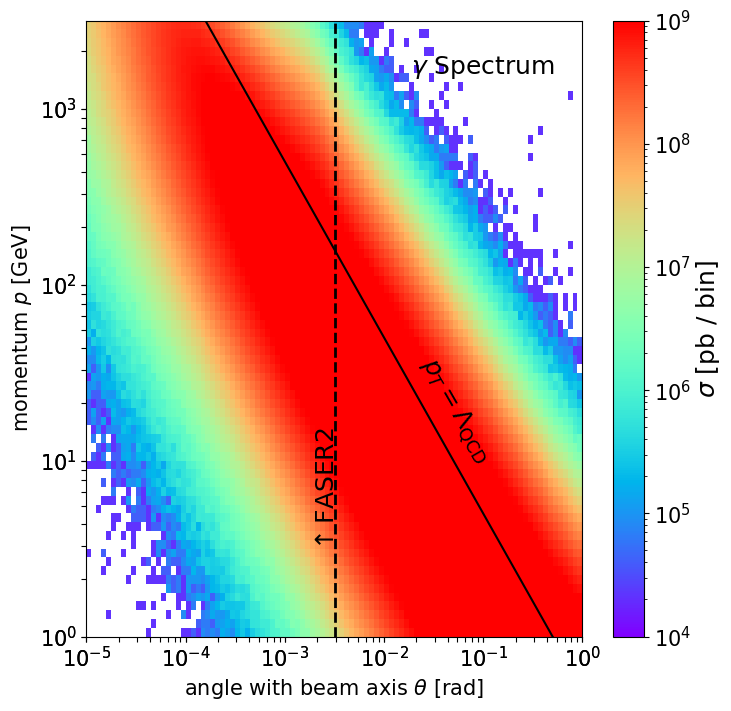

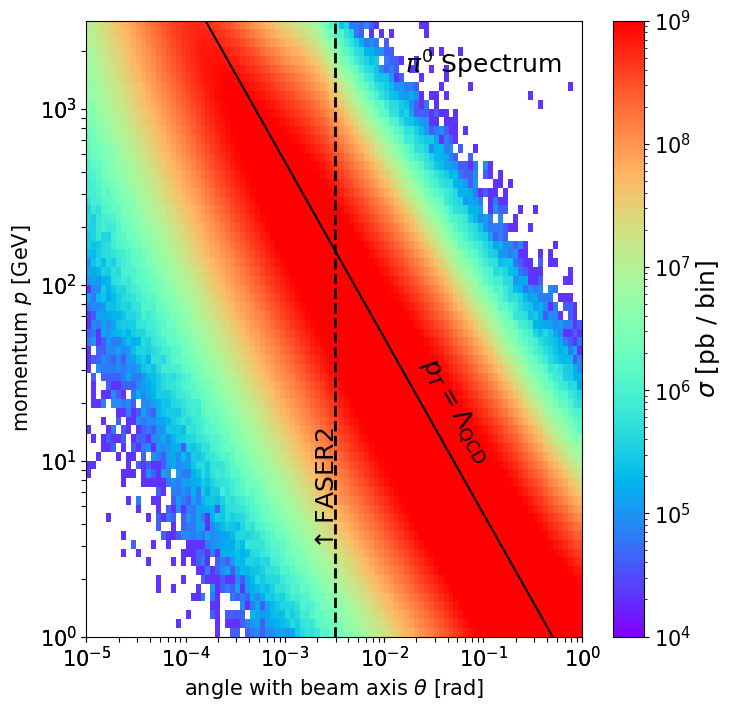

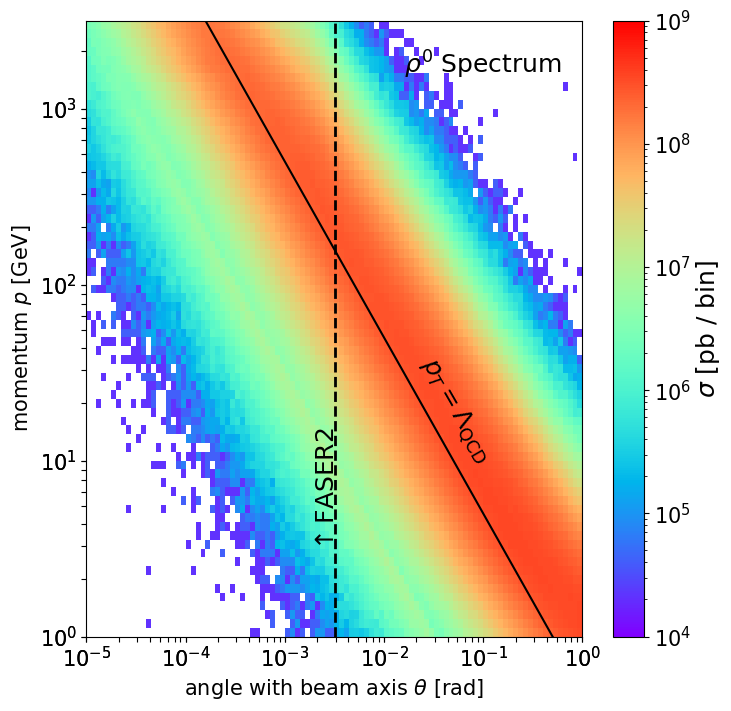

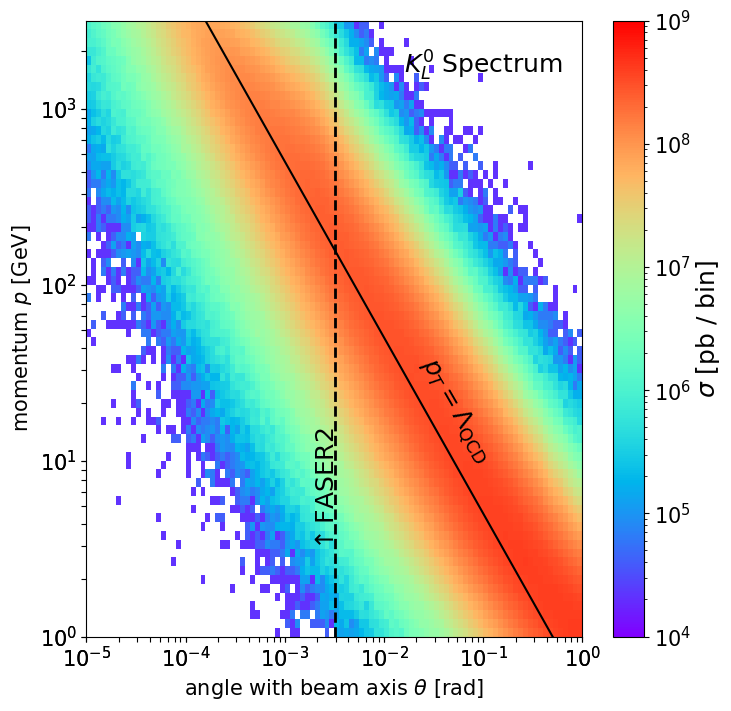

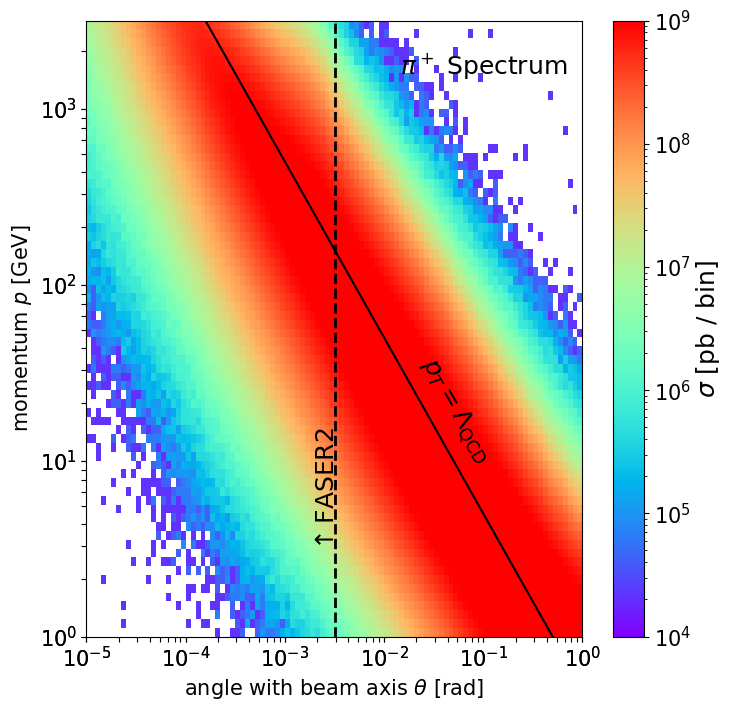

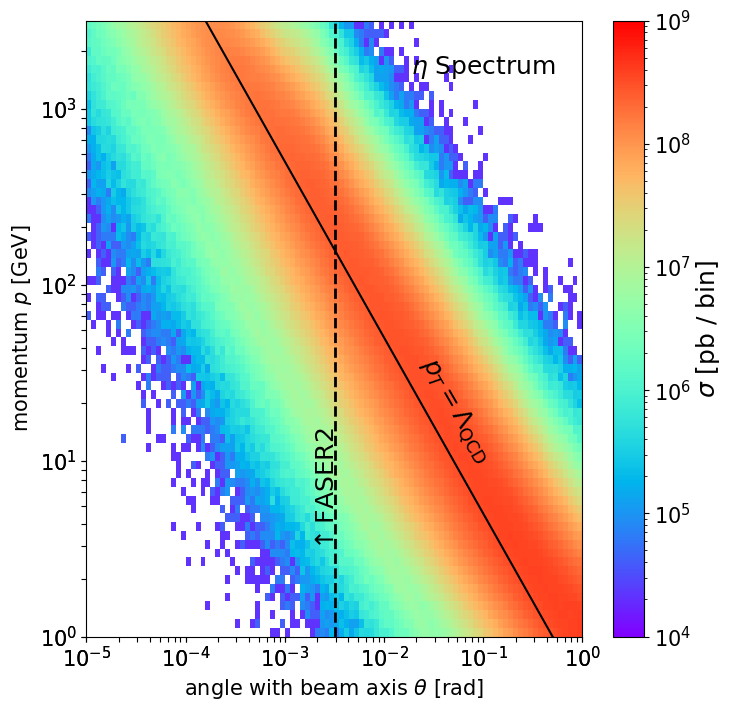

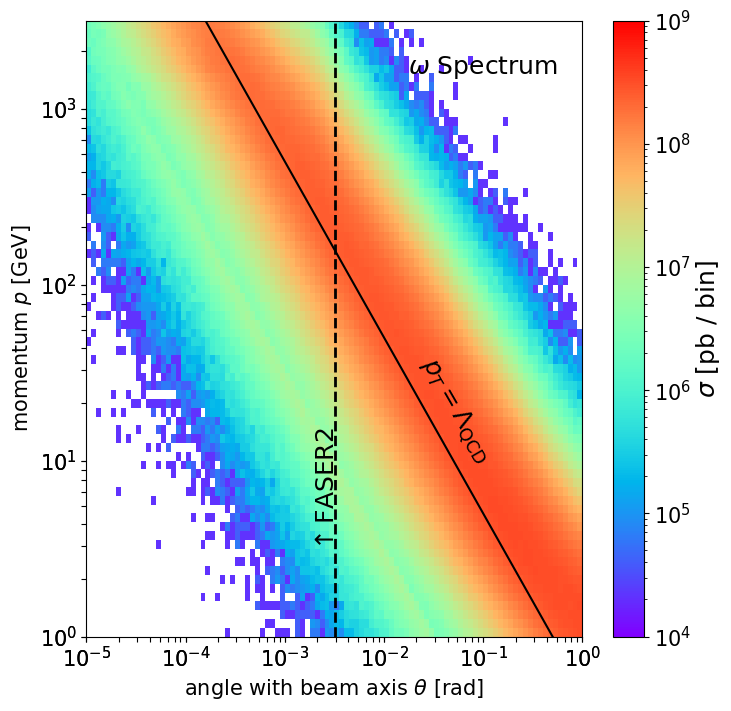

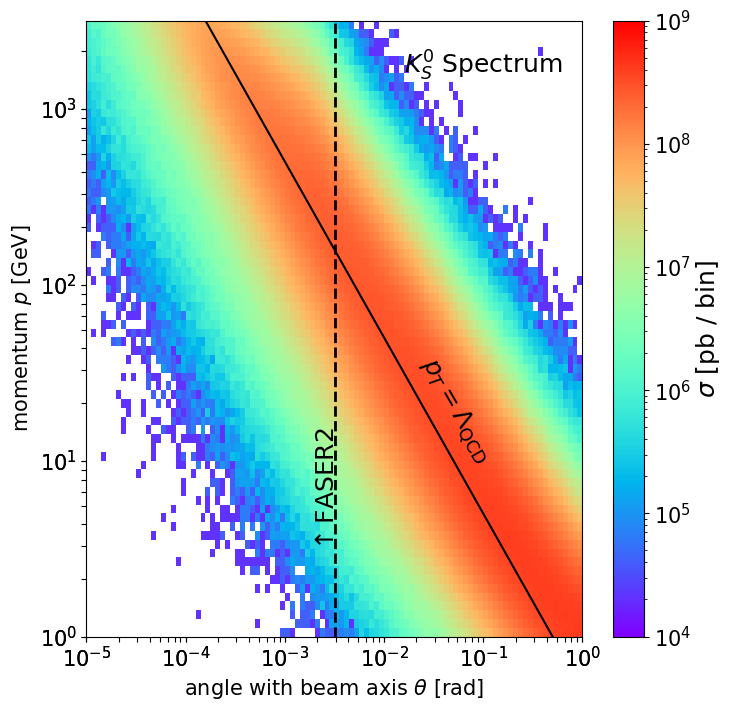

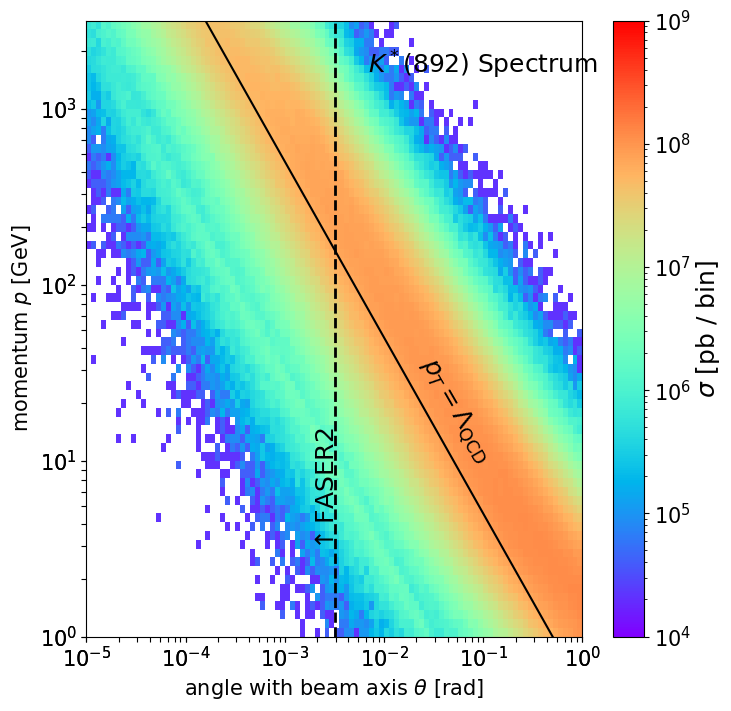

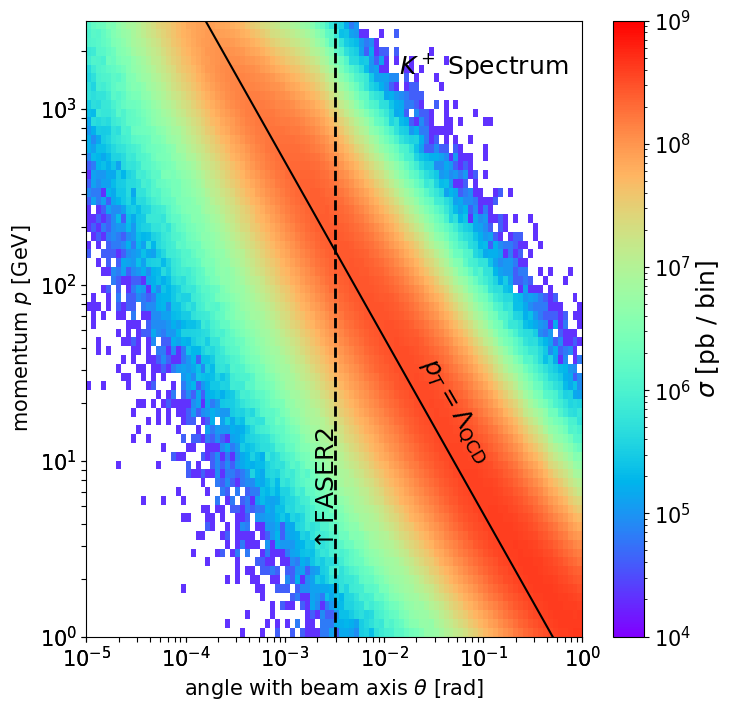

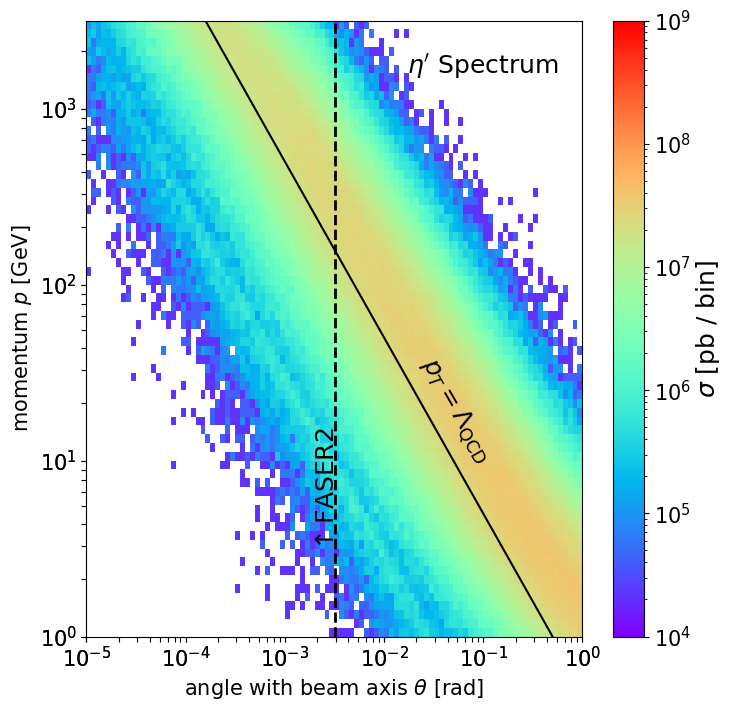

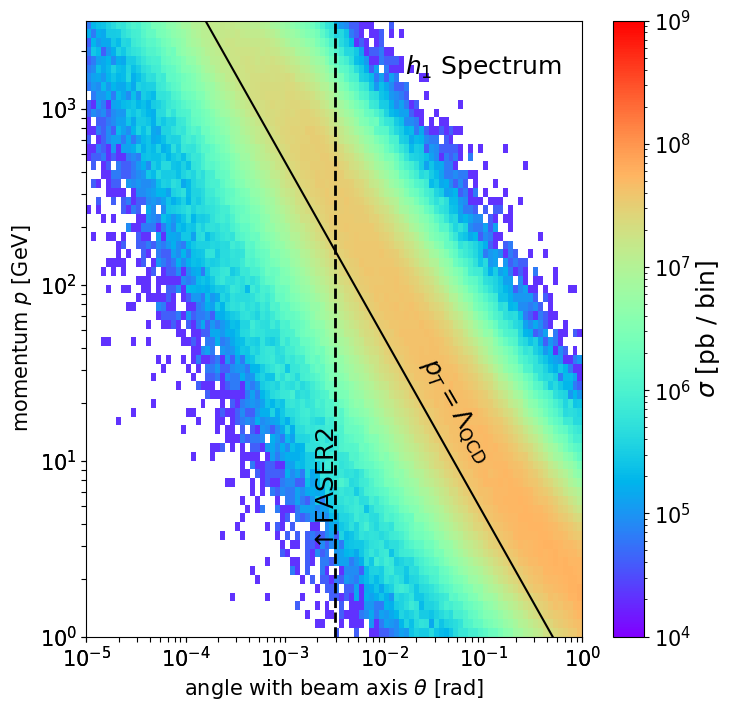

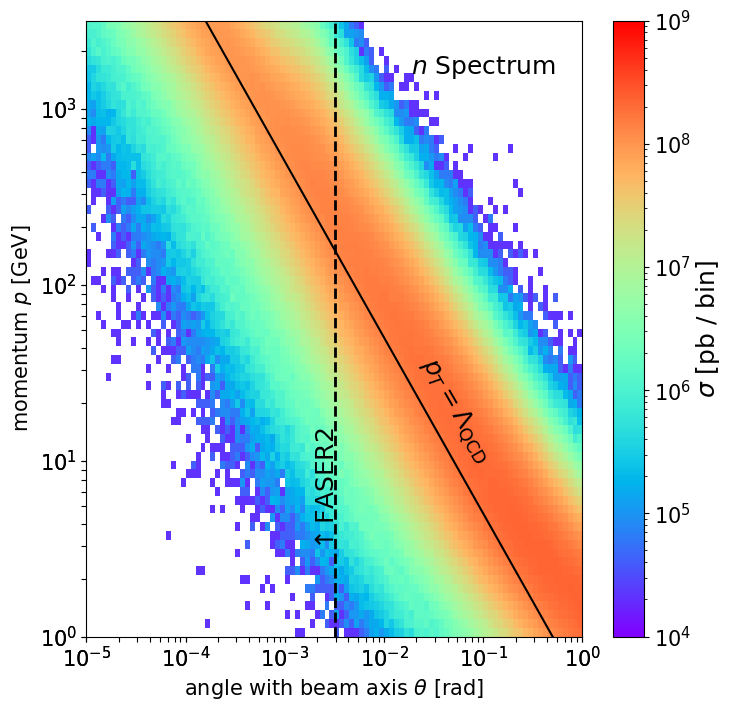

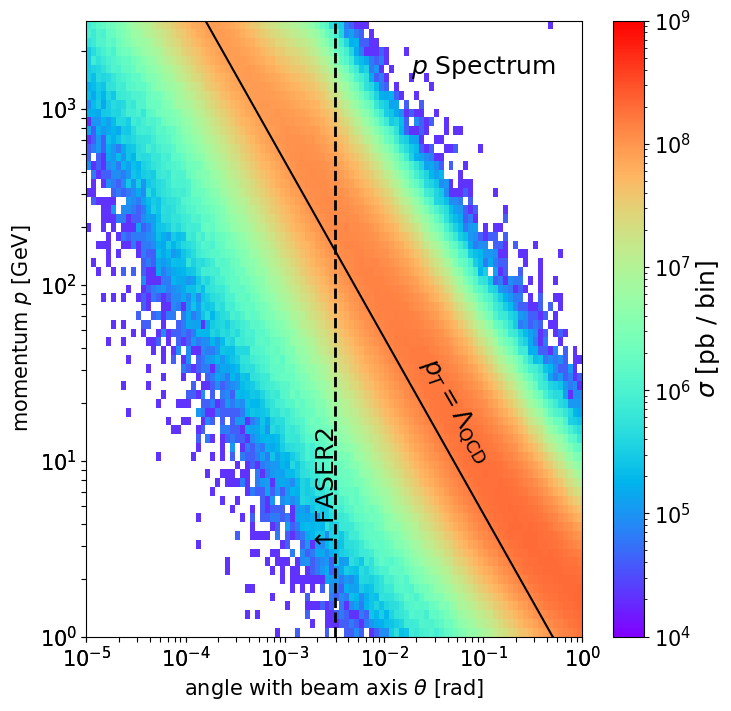

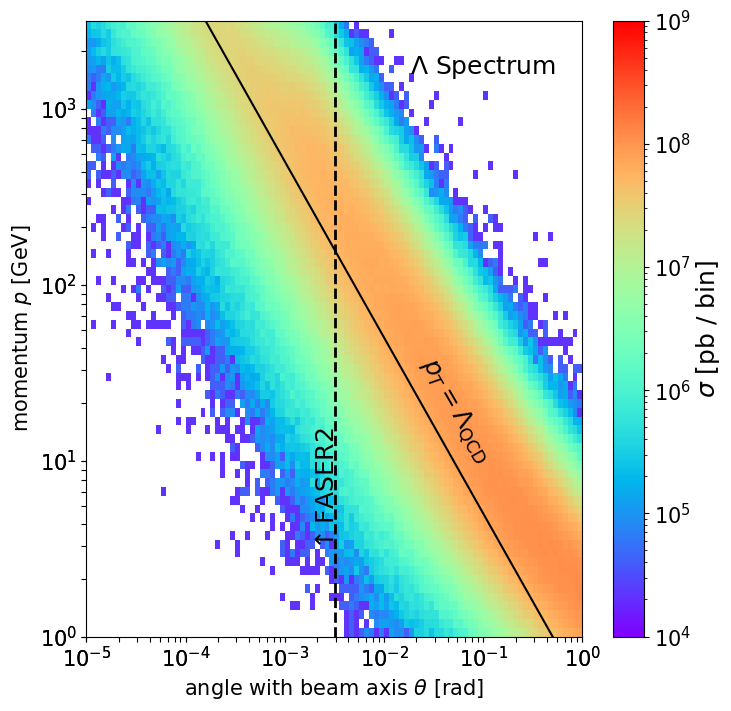

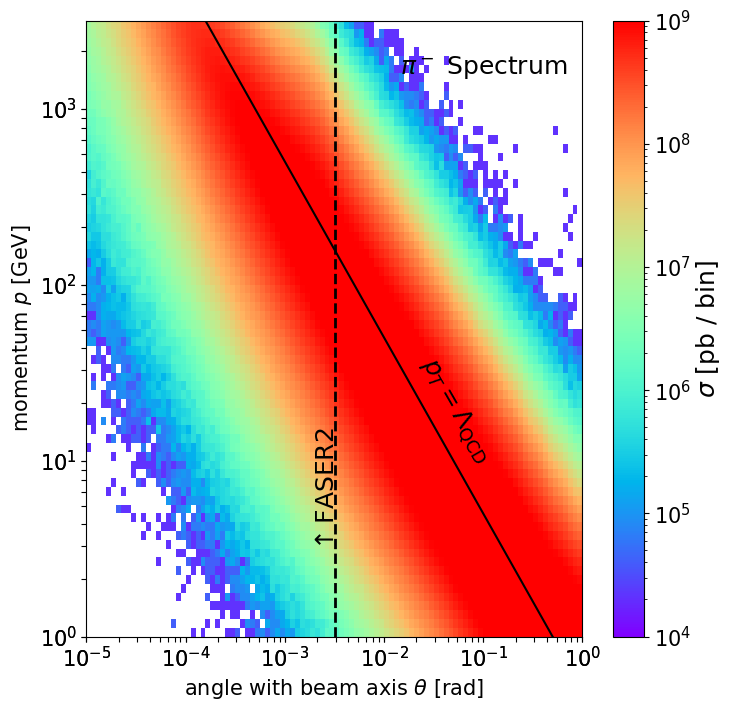

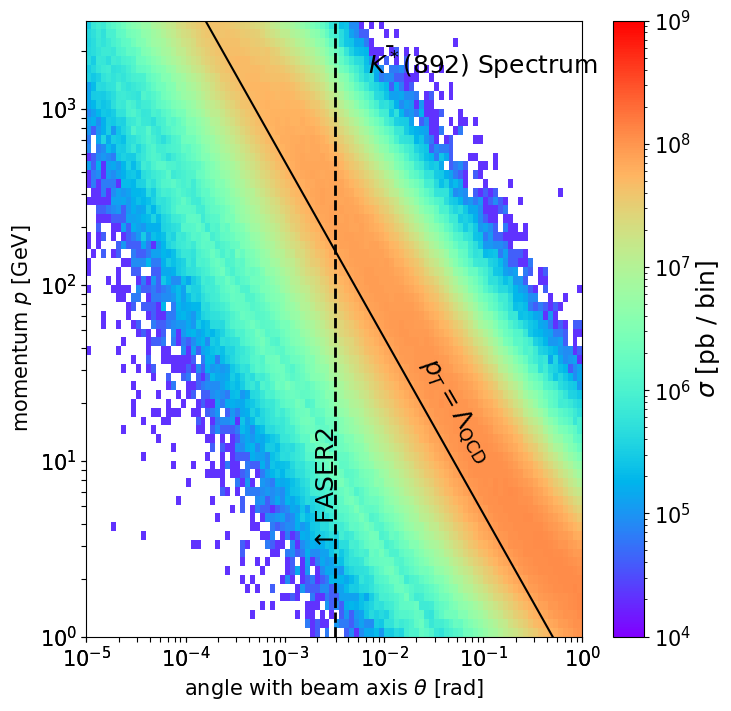

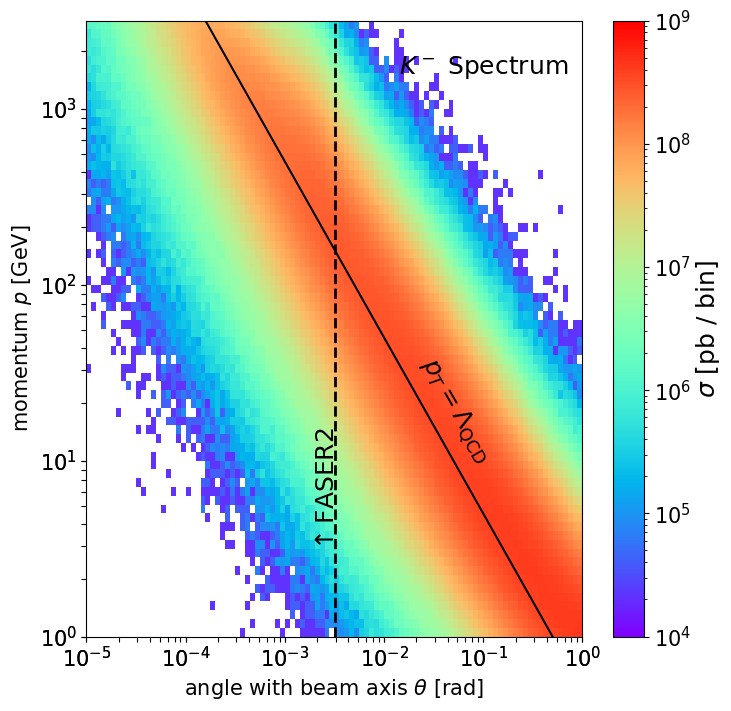

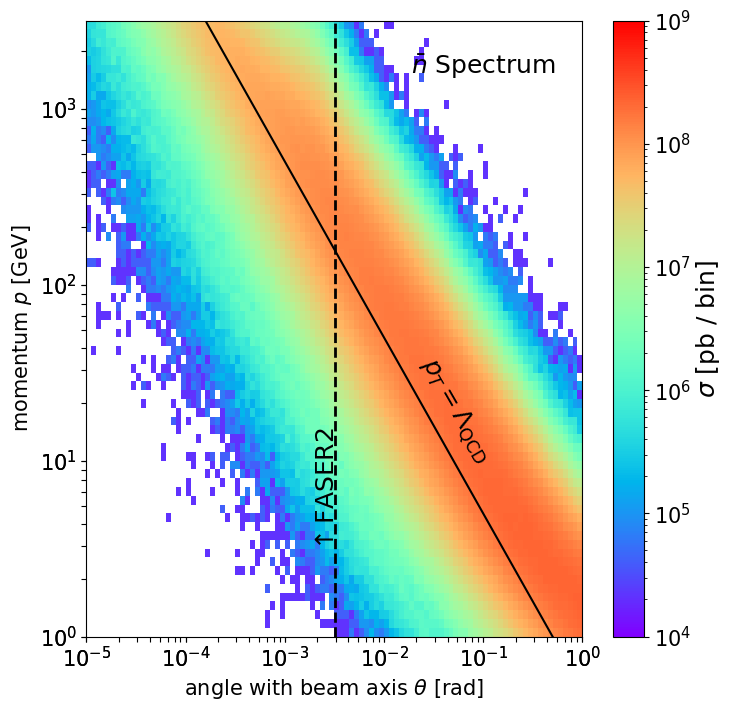

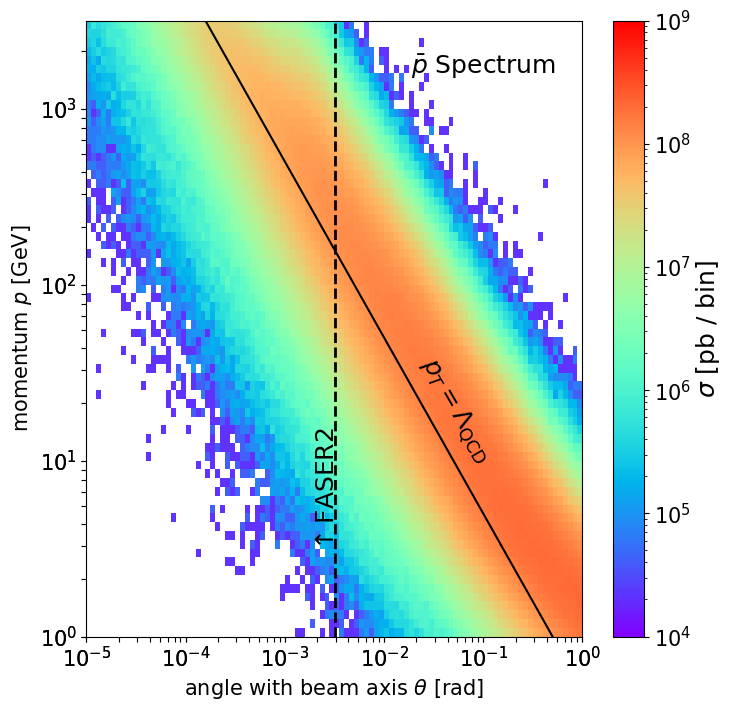

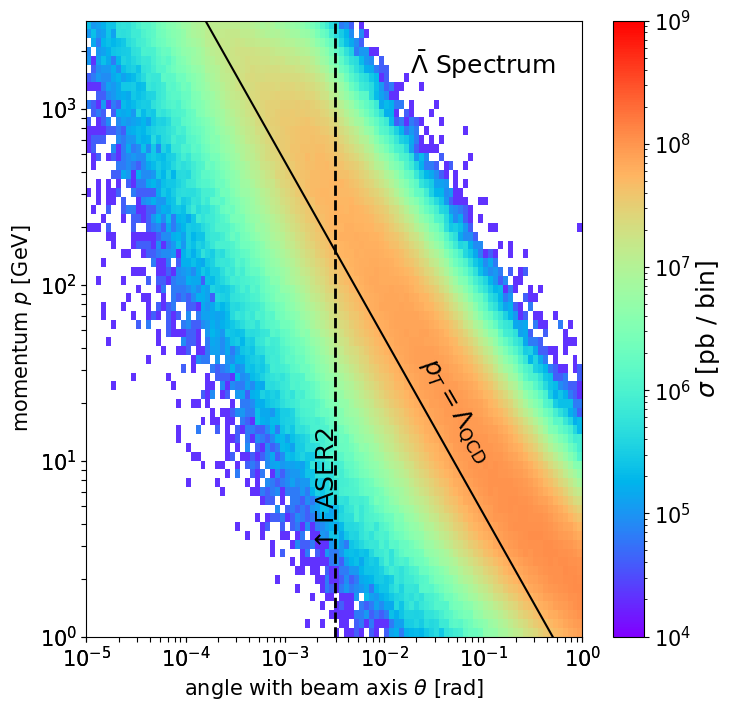

In [9]:
path = "/home/souvik/codes/foresee-main/files/hadrons/100TeV/EPOSLHC/"
pids = [str(mesons[pid]) for pid in mesons.keys()]
# masses = {"111": 0.135, "221":0.547} 
names = {}
for meson in mesons.keys():
    names[str(mesons[meson])] = meson 
for pid in pids:
    file = path+"EPOSLHC_100TeV_"+pid+".txt"
    data = np.genfromtxt(file)
    ps , ws = foresee.convert_list_to_momenta(file,masses(pid), filetype="txt",luminosity=3000, nsample=1,preselectioncut=None, 
                                      nocuts=False, mincount=0, extend_to_low_pt_scale=None)
    foresee.convert_to_hist_list(ps,ws,luminosity=1/1000, do_plot=True, filename=None, cmap="rainbow",
                         do_return=False, prange=[[-5, 0, 100],[0, 3.5, 70]], vmin=1e4, vmax=1e9)
    
    plt.gca()
    plt.axvline(x=np.log10(5/1550), color='black', linestyle='--', linewidth=2)

    ts = [p.pt/p.p for p in ps]
    x = [np.log10(t) for t in ts]
    y = [np.log10(0.5)-i for i in x]
    plt.plot(x, y, color="black")
    plt.text(-2.7, 0.5, r"$\uparrow$FASER2", fontsize=18, rotation=90)
    
    plt.title(r""+names[pid]+" Spectrum", y=0.9, x=0.8)
    plt.text(-1.7, 1, r"$p_T=\Lambda_\text{QCD}$", fontsize=18, rotation=-60)
    
    plt.xlabel(r"angle with beam axis $\theta$ [rad]")
    plt.ylabel(r"momentum $p$ [GeV]")
    plt.savefig(r"/home/souvik/codes/FORESEE_fig/spectrum_100/"+pid+".png")
    plt.show()

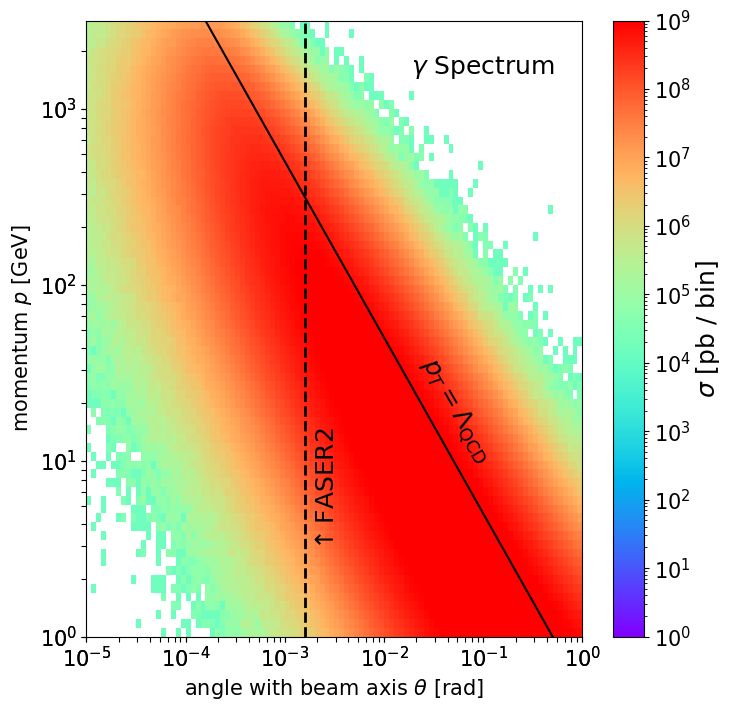

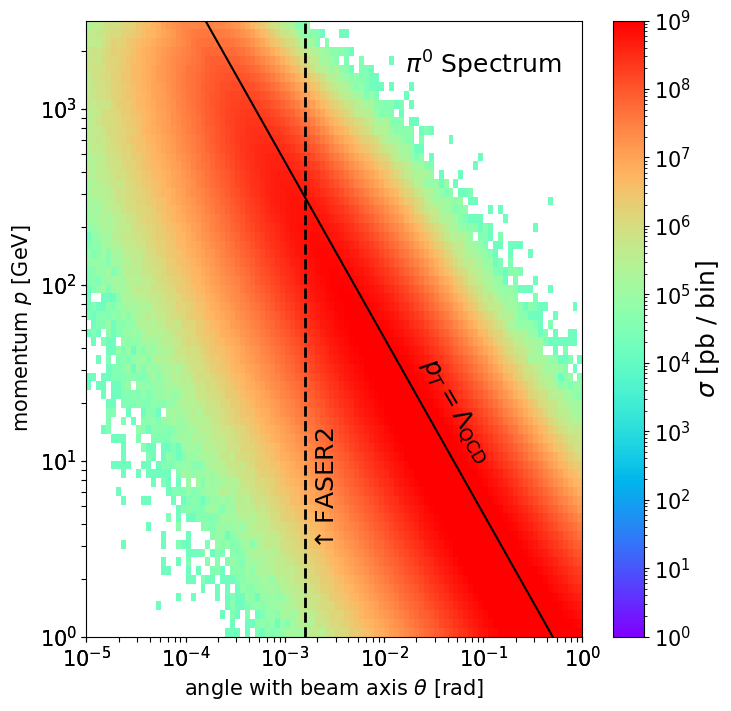

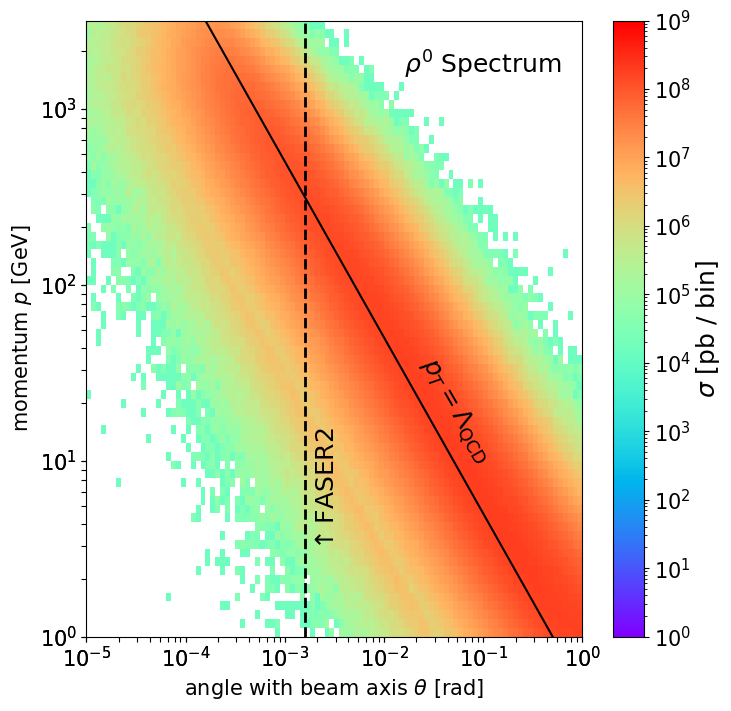

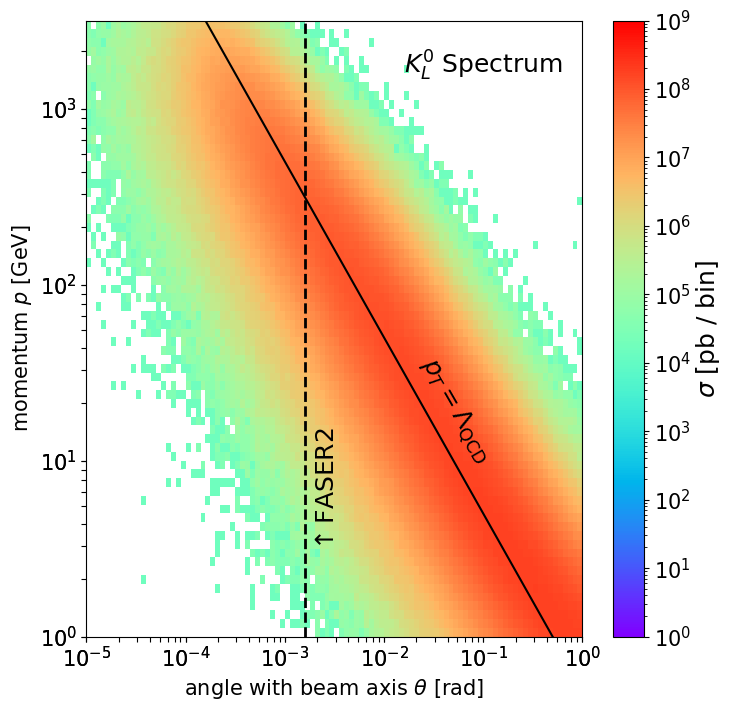

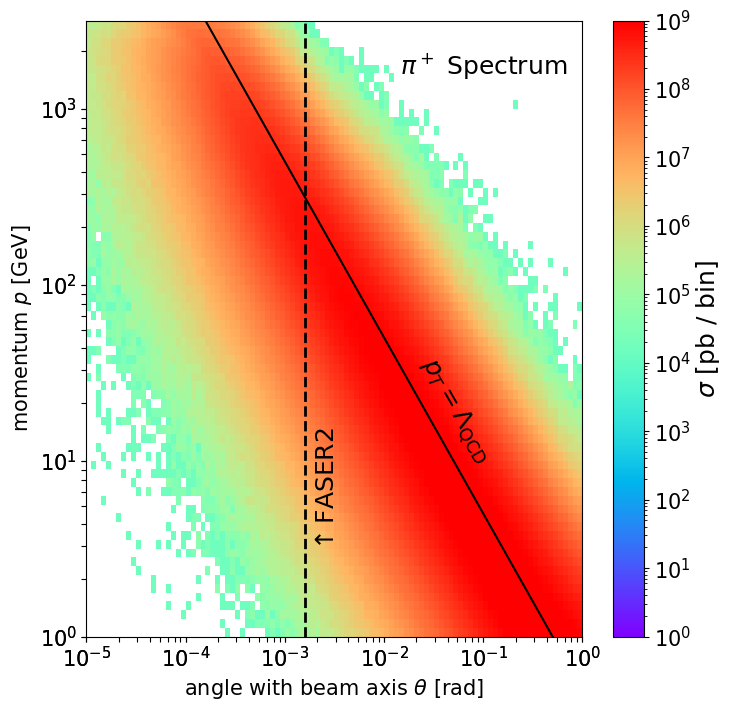

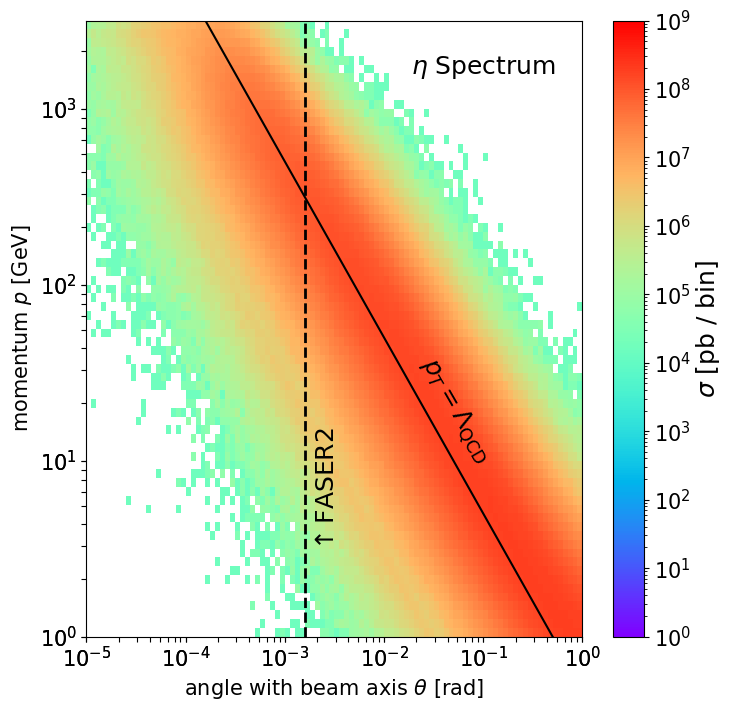

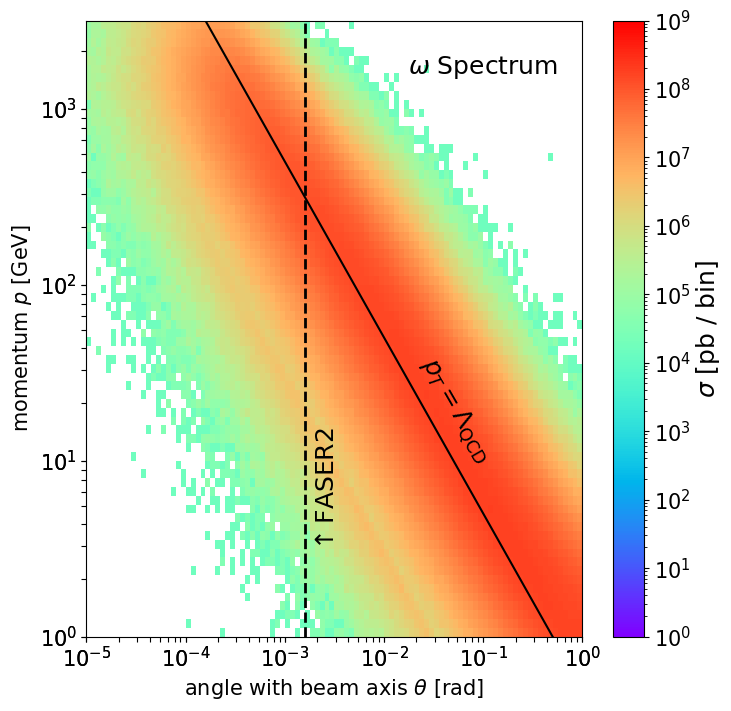

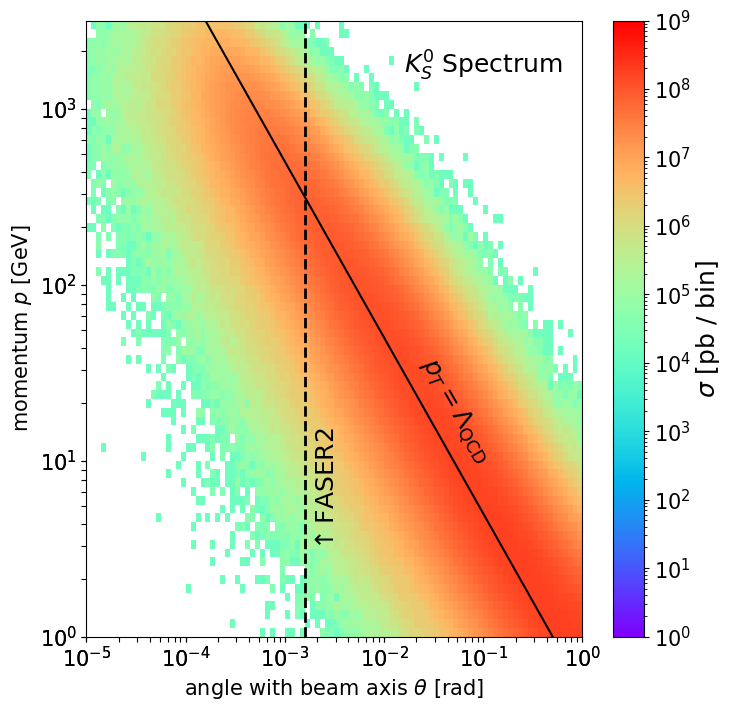

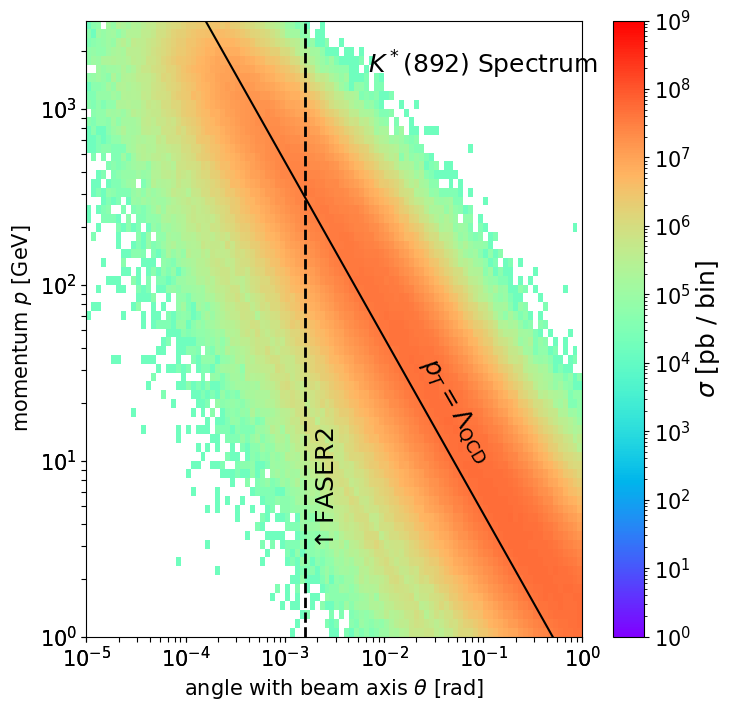

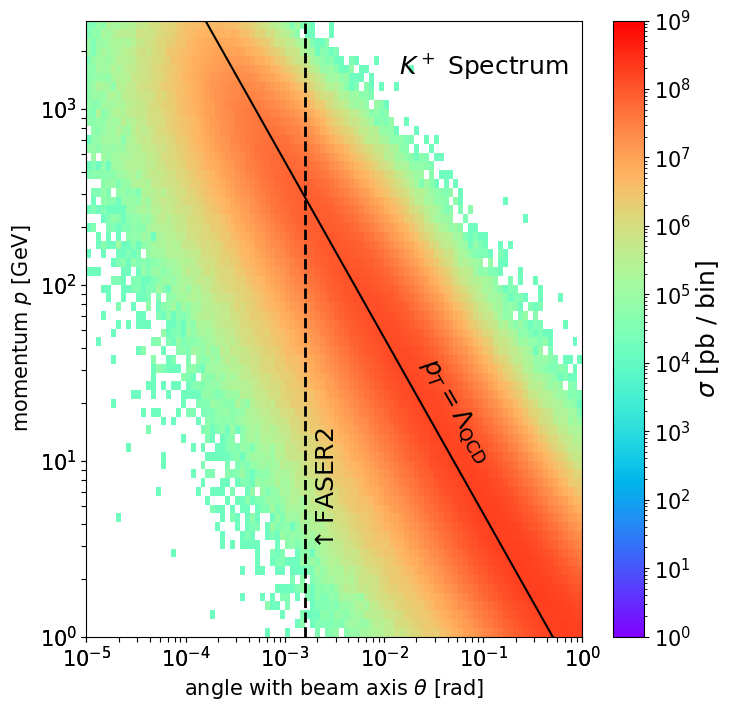

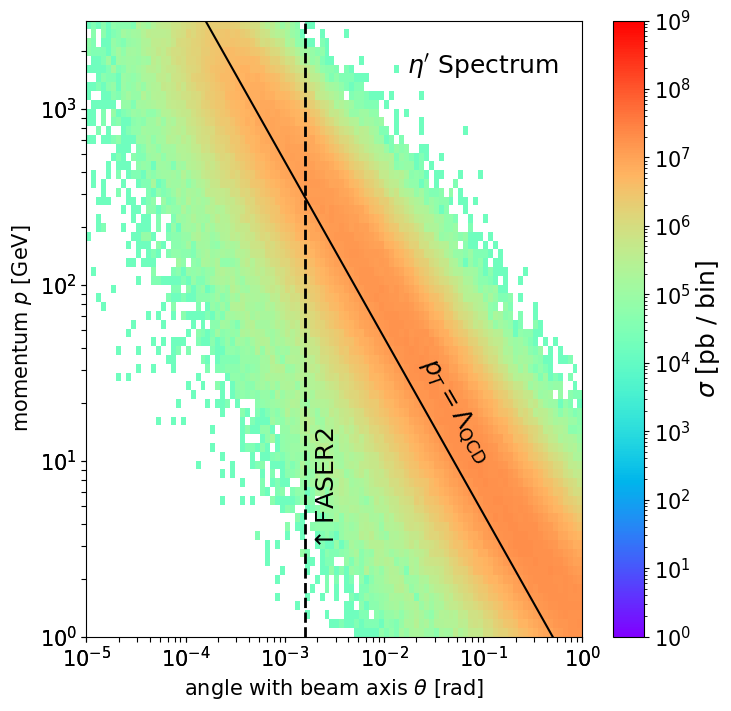

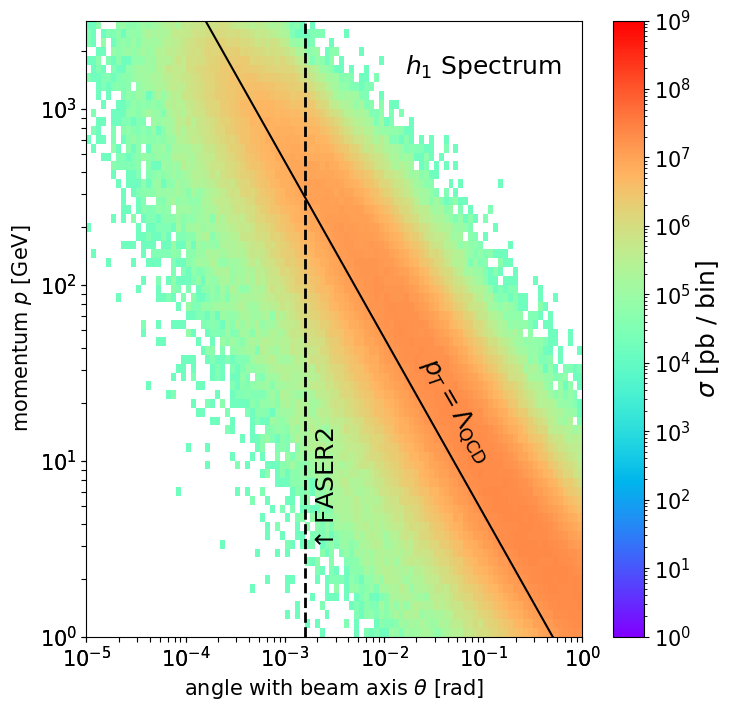

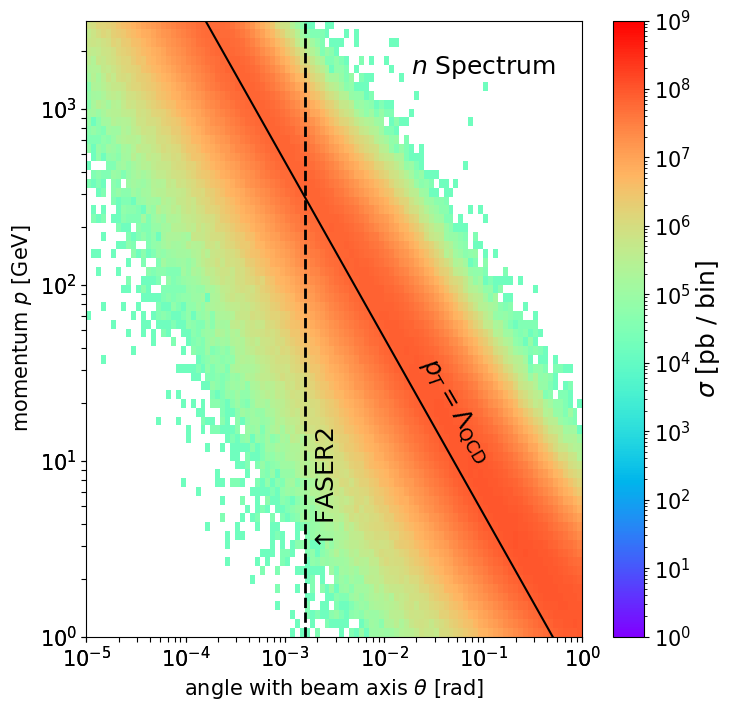

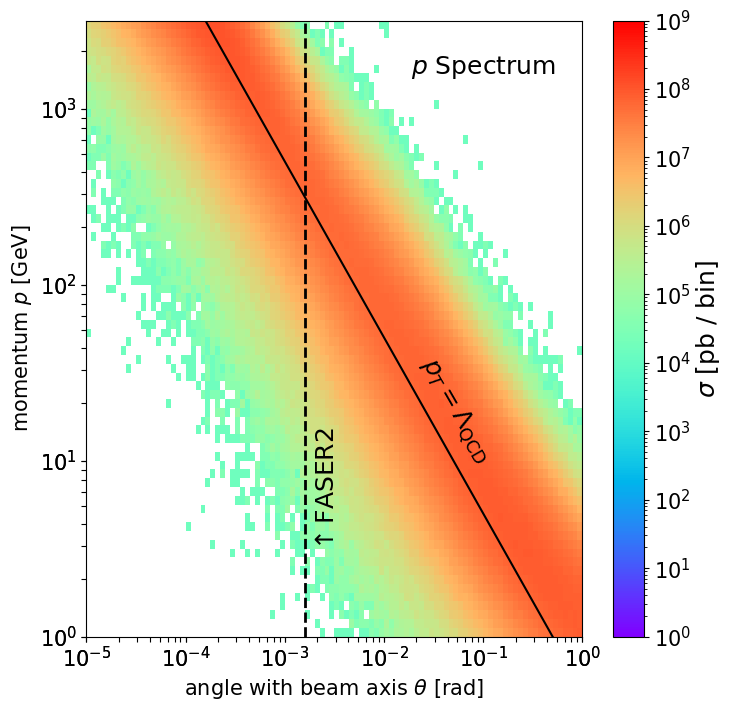

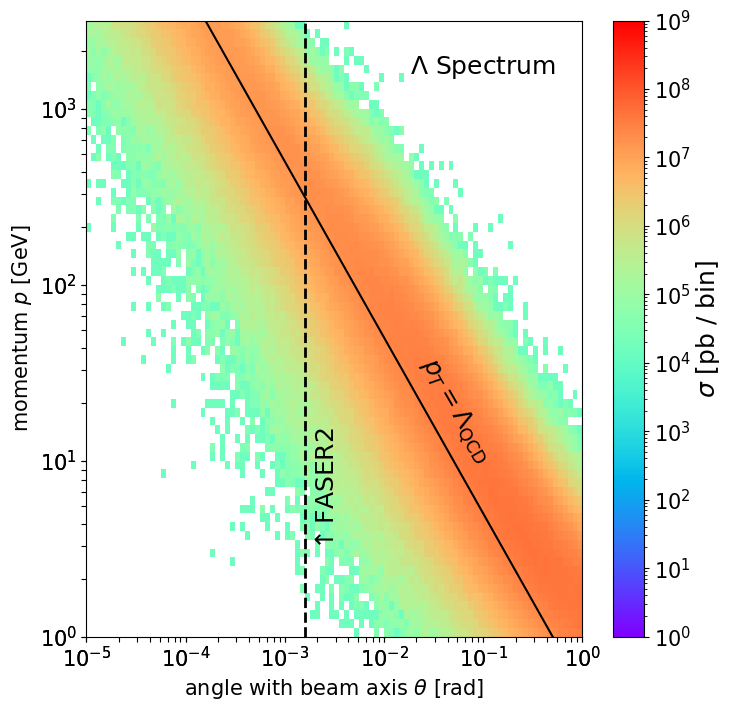

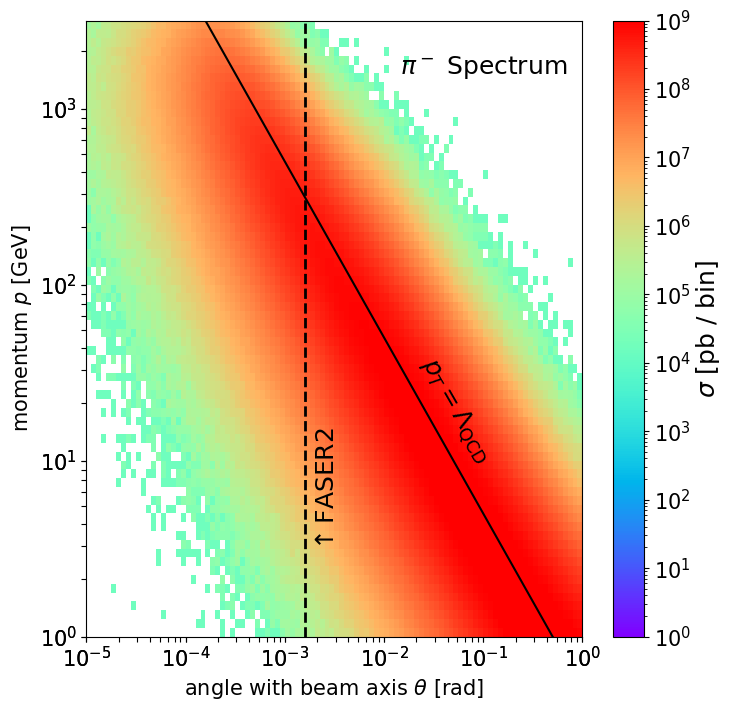

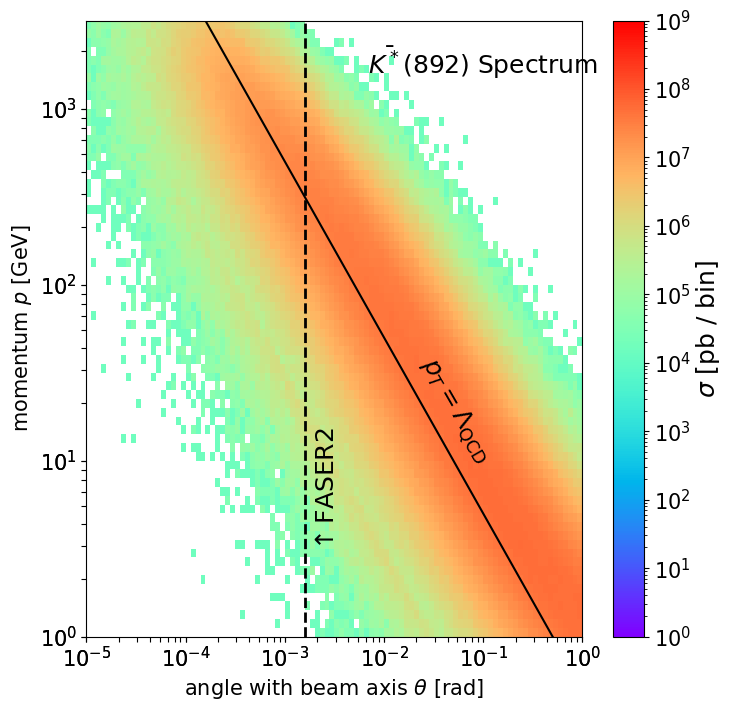

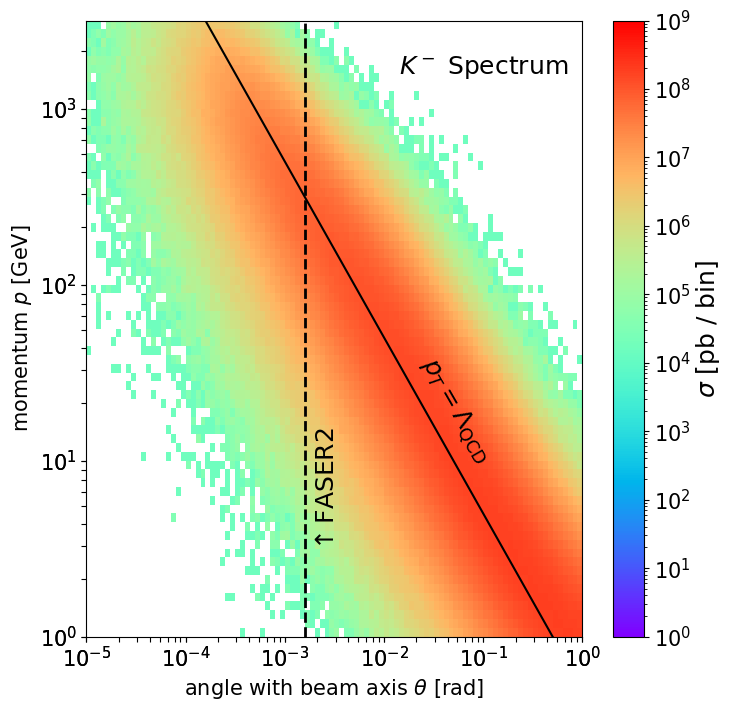

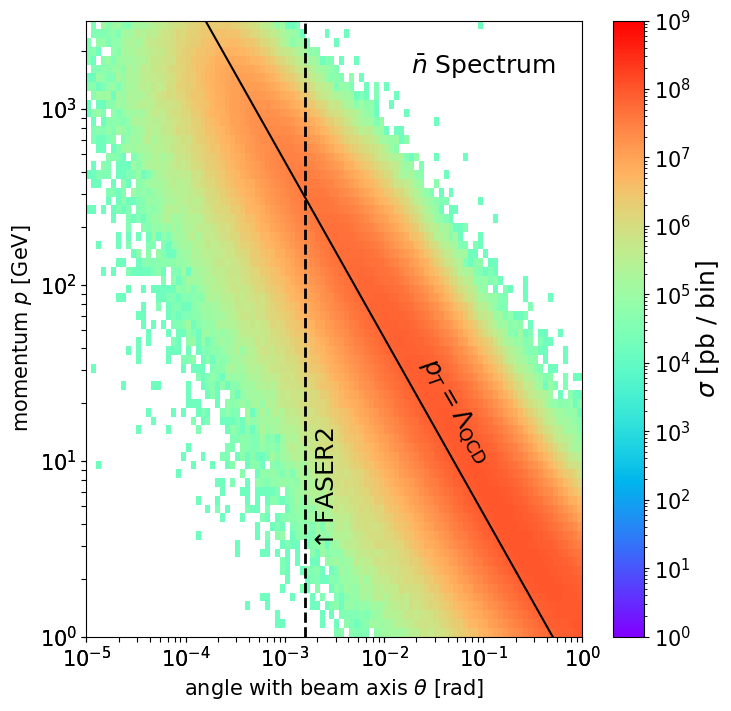

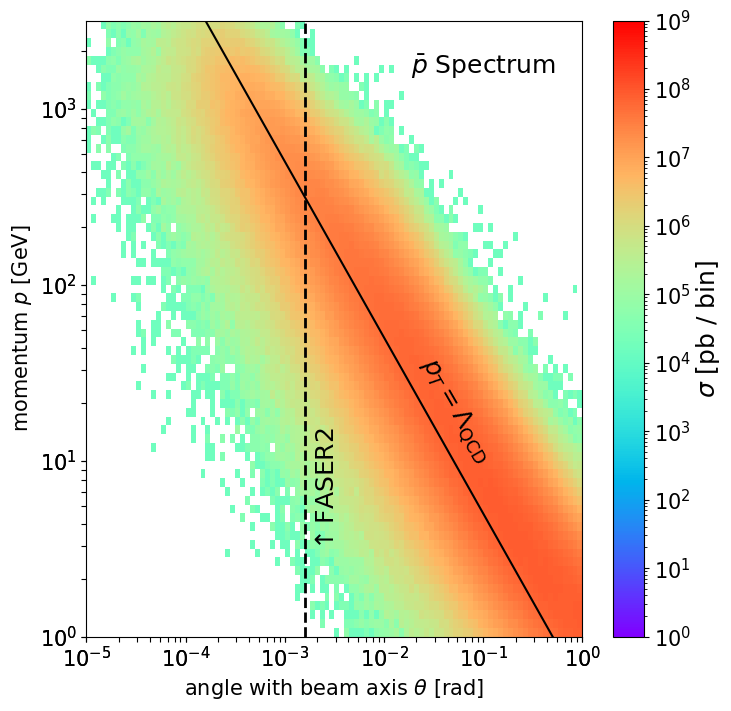

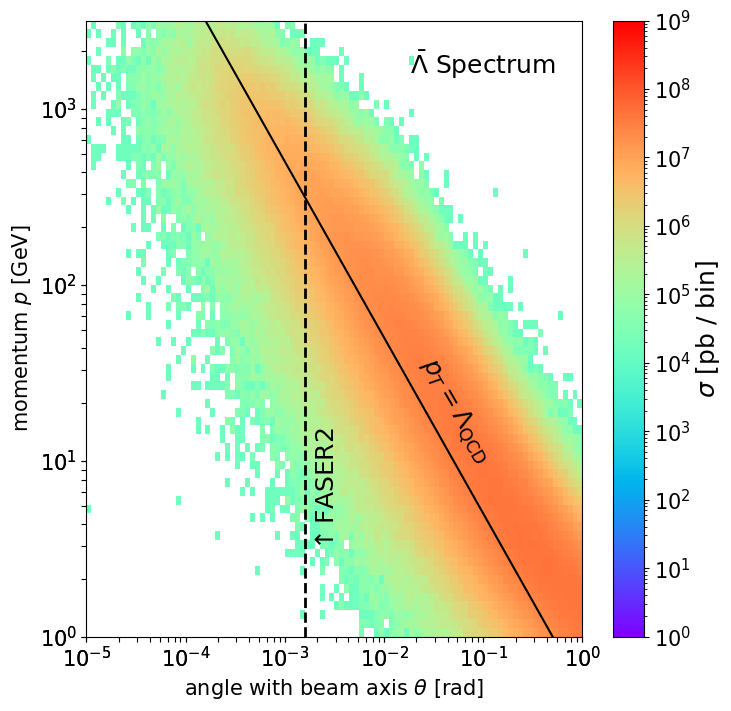

In [14]:
path = "/home/souvik/codes/foresee-main/files/hadrons/14TeV/EPOSLHC/"
pids = [str(mesons[pid]) for pid in mesons.keys()]
# masses = {"111": 0.135, "221":0.547} 
names = {}
for meson in mesons.keys():
    names[str(mesons[meson])] = meson 
xlabels = {"111": r"$\theta_{\pi^0}$ [rad]", "221": r"$\theta_{\eta}$ [rad]"}
ylabels = {"111": r"p$_{\pi^0}$ [GeV]" , "221": r"p$_{\eta}$ [GeV]"}
for pid in pids:
    file = path+"EPOSLHC_14TeV_"+pid+".txt"
    data = np.genfromtxt(file)
    ps , ws = foresee.convert_list_to_momenta(file,masses(pid), filetype="txt",luminosity=3000, nsample=1,preselectioncut=None, 
                                      nocuts=False, mincount=0, extend_to_low_pt_scale=None)
    foresee.convert_to_hist_list(ps,ws,luminosity=1/1000, do_plot=True, filename=None, cmap="rainbow",
                         do_return=False, prange=[[-5, 0, 100],[0, 3.5, 70]], vmin=1, vmax=1e9)
    
    plt.gca()
    plt.axvline(x=np.log10(1/630), color='black', linestyle='--', linewidth=2)

    ts = [p.pt/p.p for p in ps]
    x = [np.log10(t) for t in ts]
    y = [np.log10(0.5)-i for i in x]
    plt.plot(x, y, color="black")
    plt.text(-2.7, 0.5, r"$\uparrow$FASER2", fontsize=18, rotation=90)
    
    plt.title(r""+names[pid]+" Spectrum", y=0.9, x=0.8)
    plt.text(-1.7, 1, r"$p_T=\Lambda_\text{QCD}$", fontsize=18, rotation=-60)
    
    plt.xlabel(r"angle with beam axis $\theta$ [rad]")
    plt.ylabel(r"momentum $p$ [GeV]")
    plt.savefig(r"/home/souvik/codes/FORESEE_fig/spectrum_14/"+pid+".png")
    plt.show()

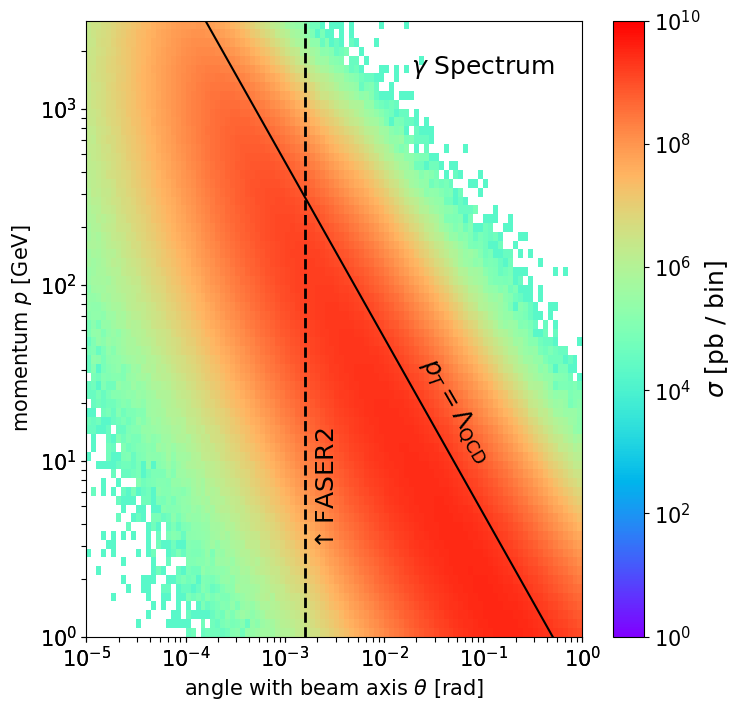

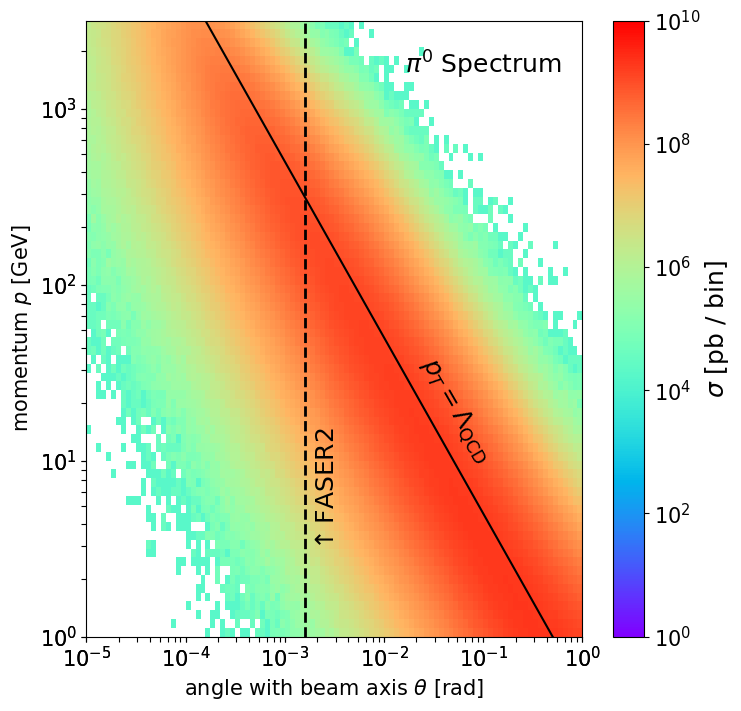

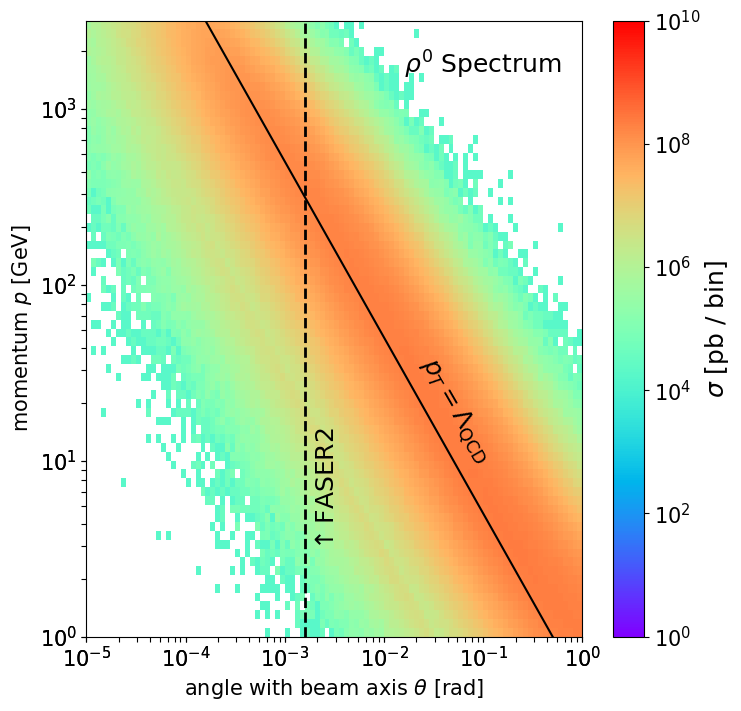

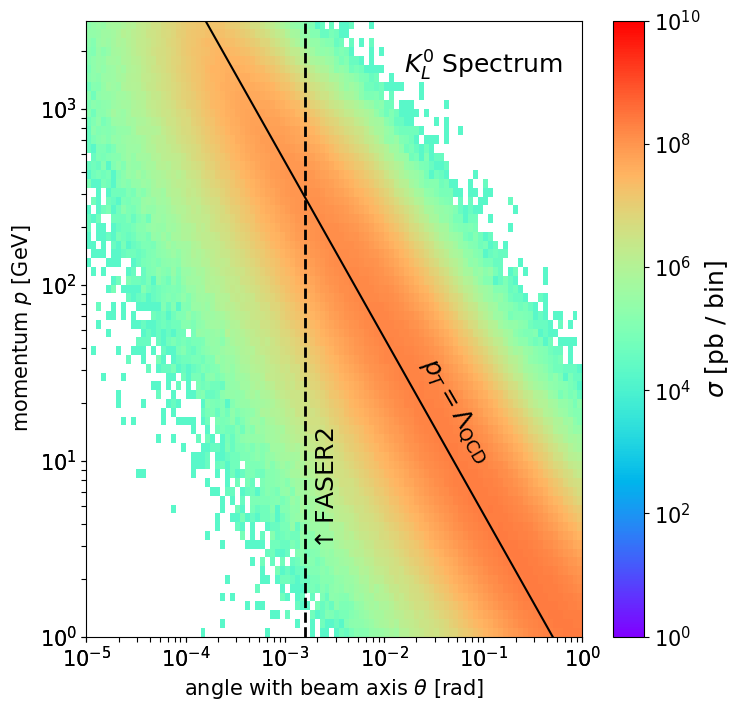

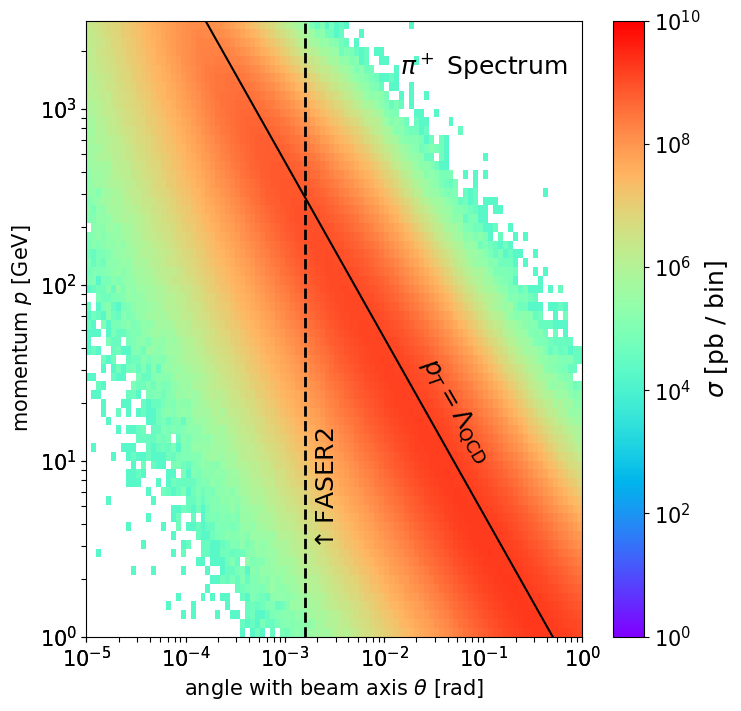

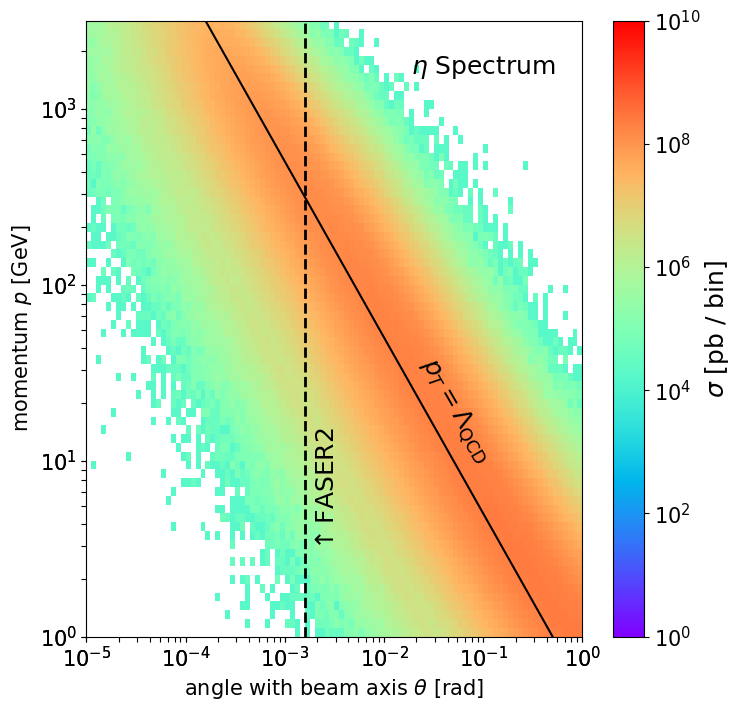

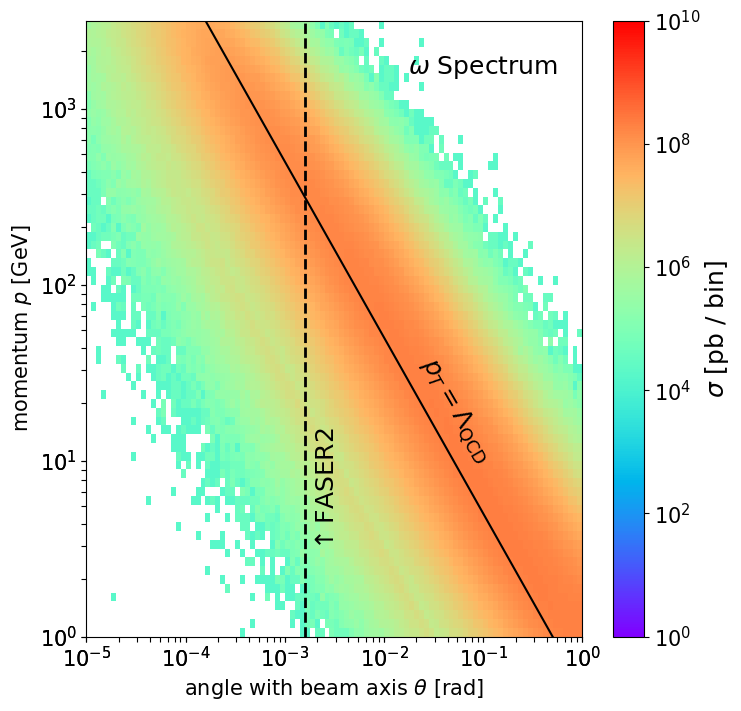

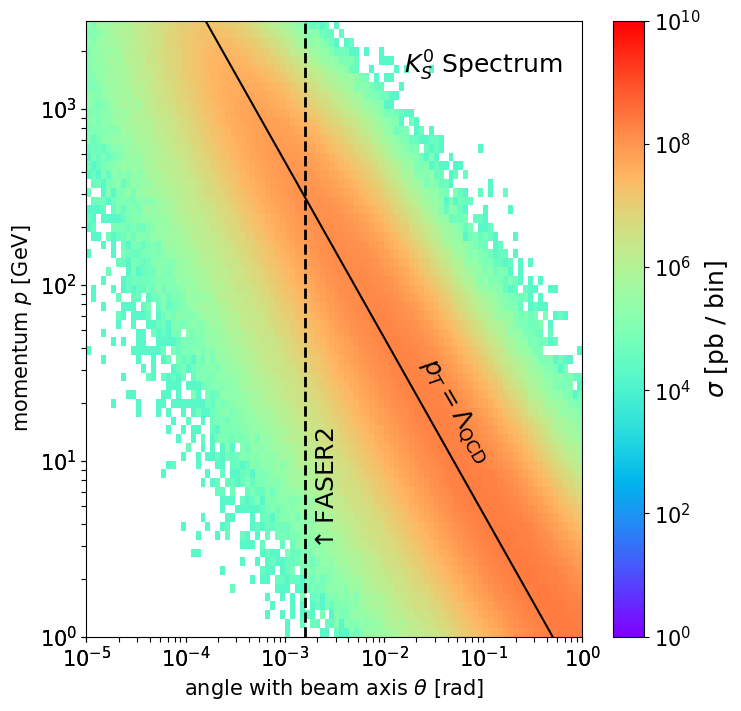

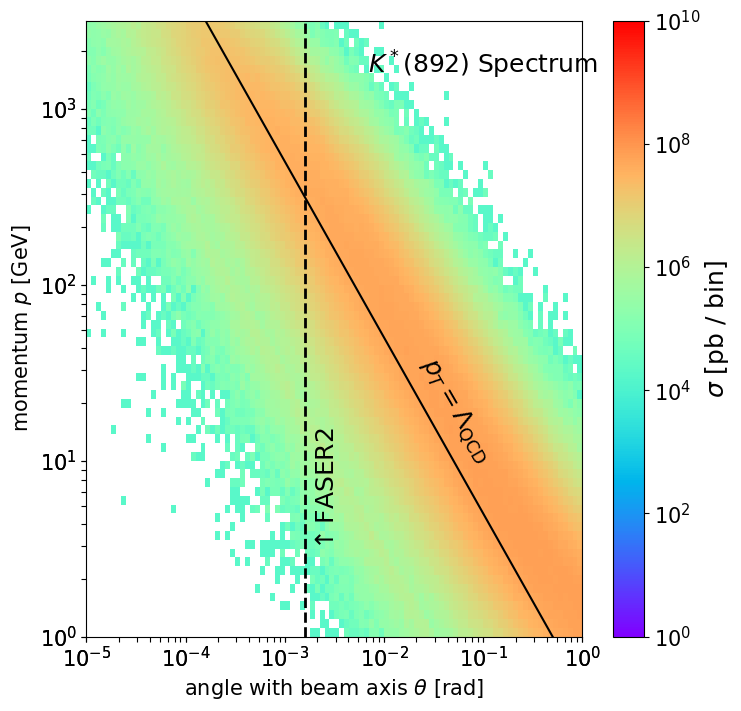

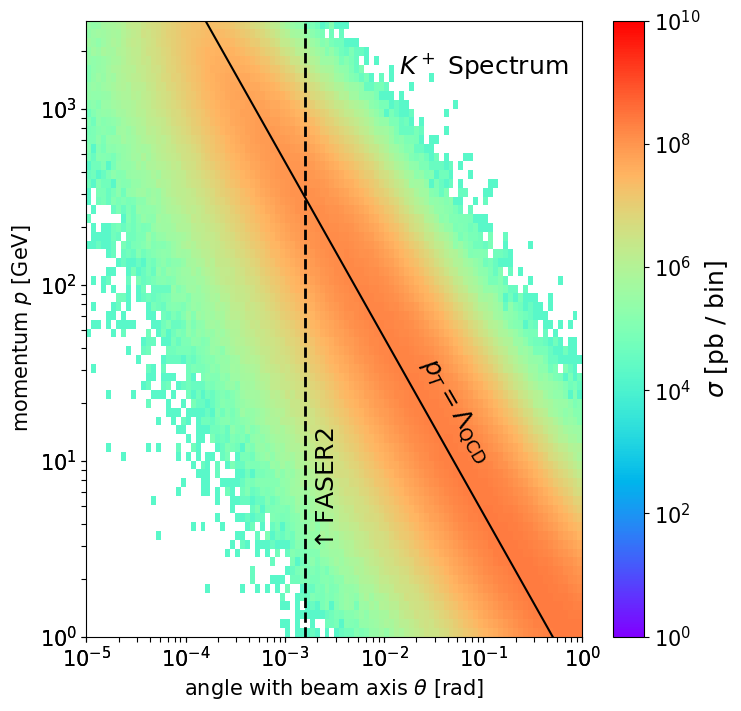

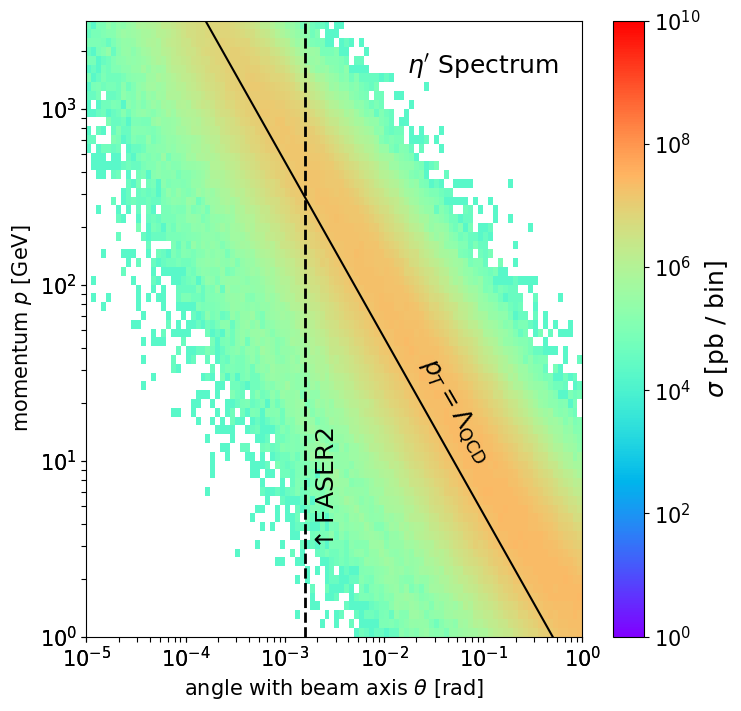

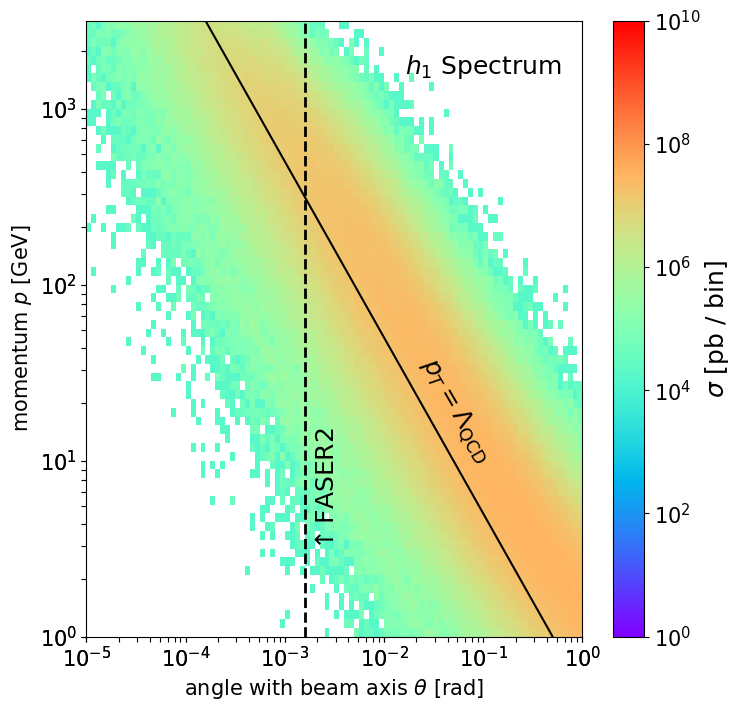

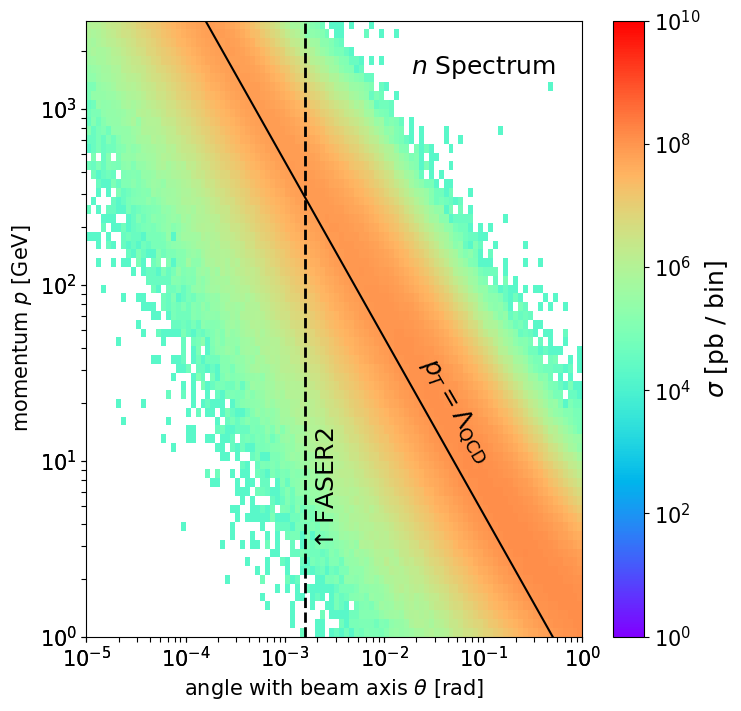

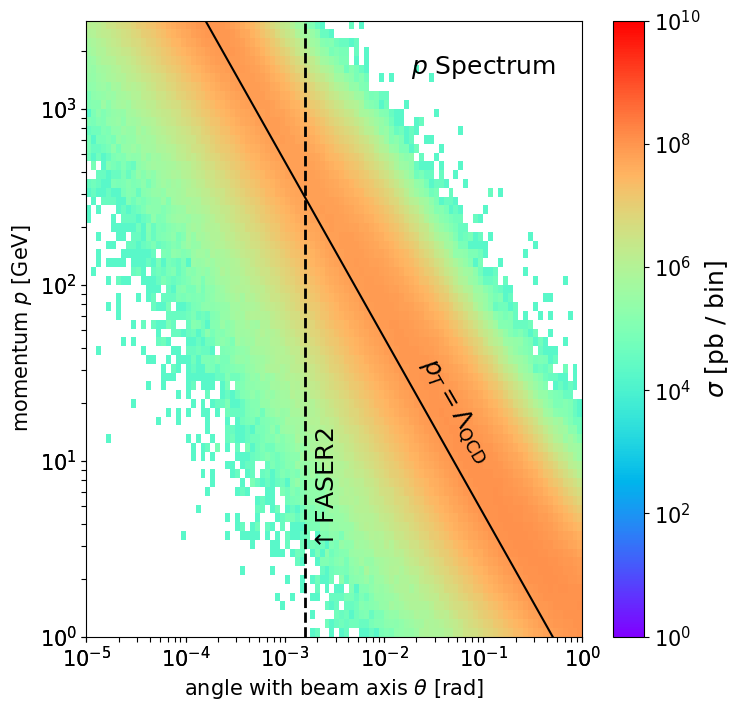

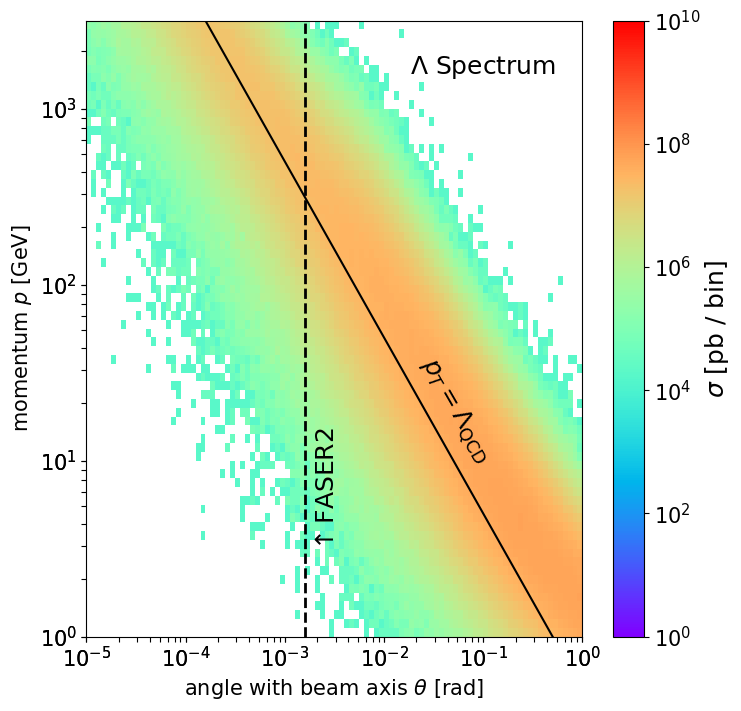

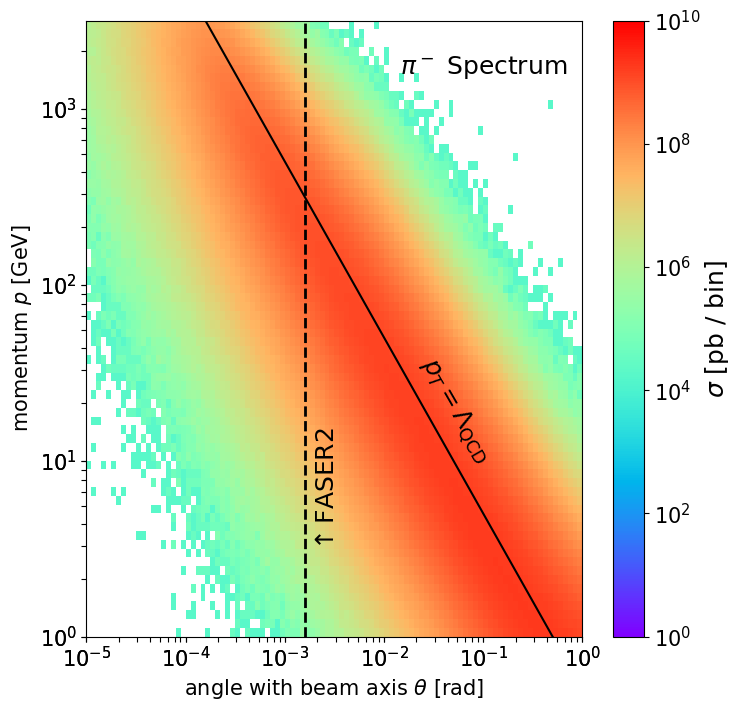

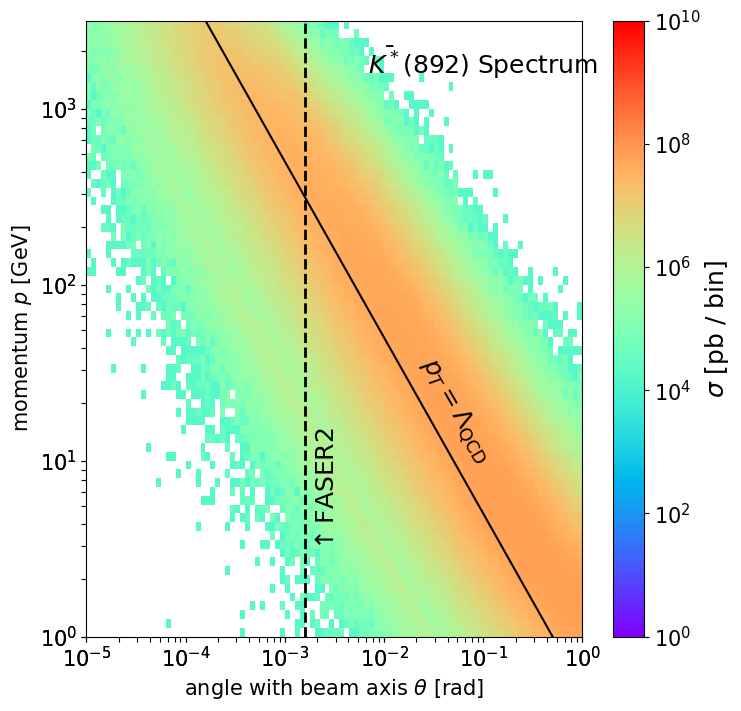

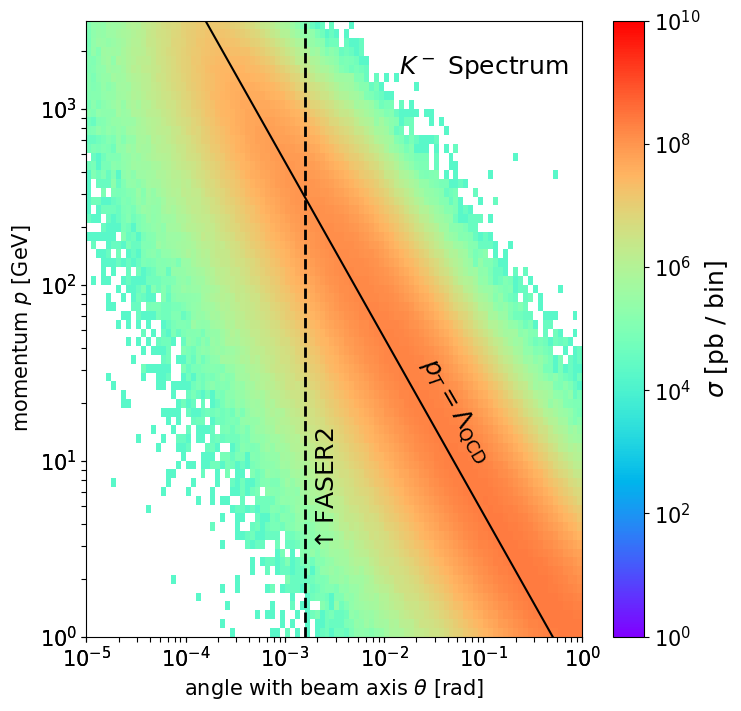

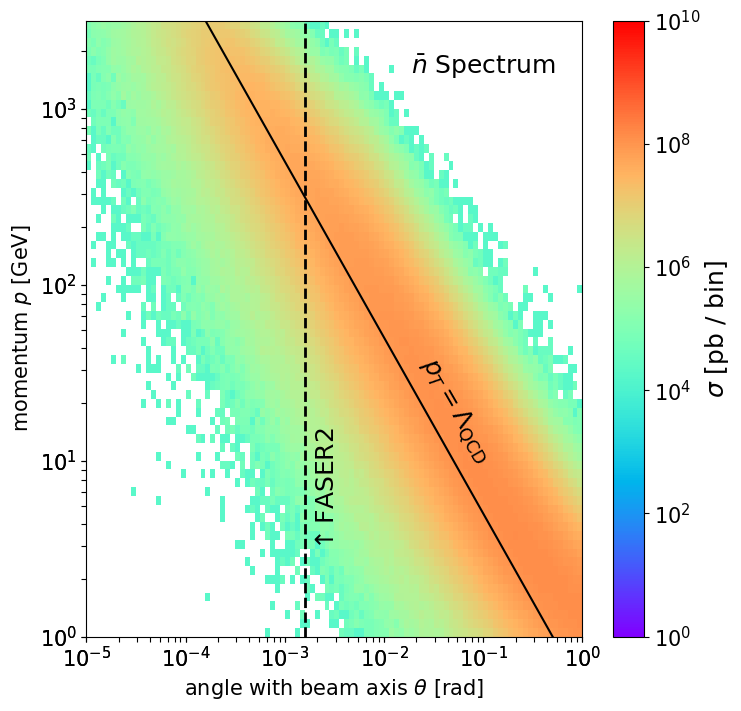

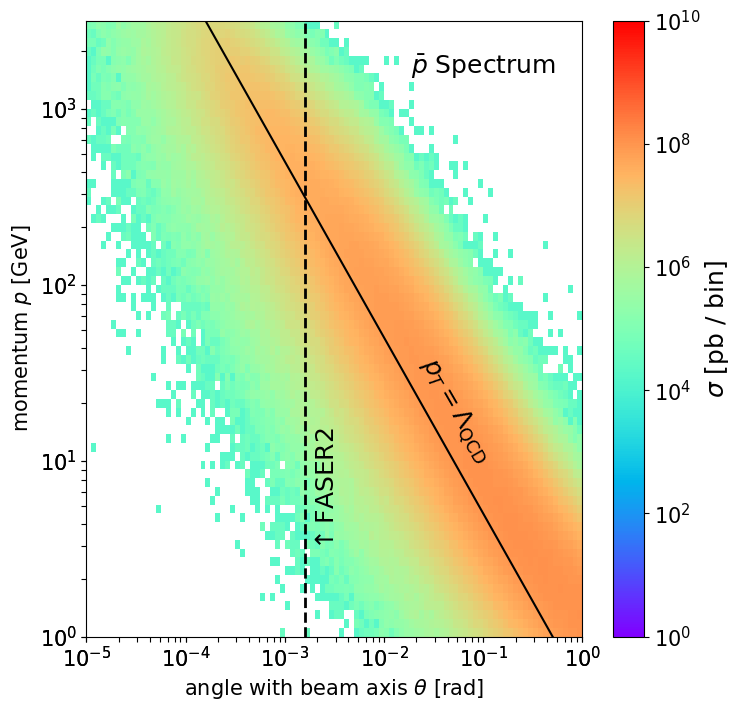

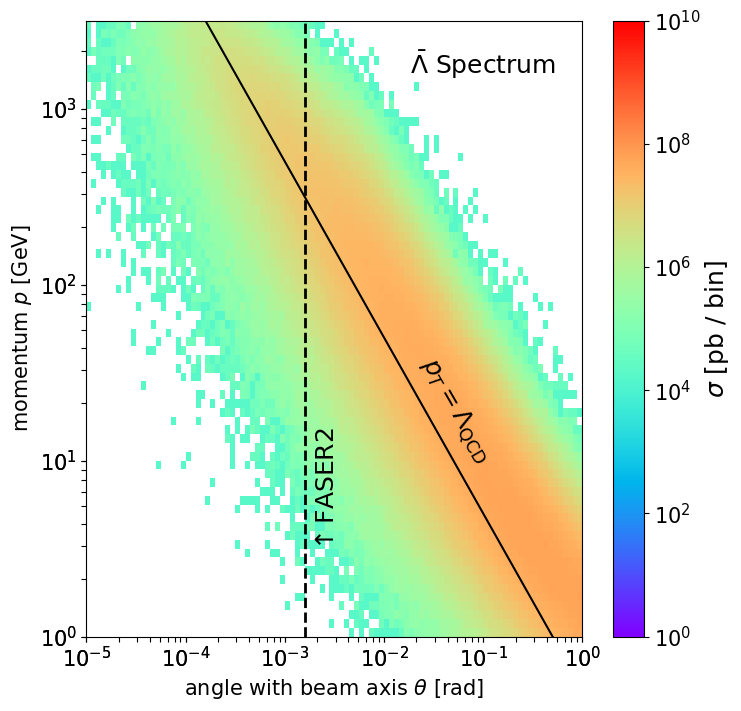

In [23]:
path = "/home/souvik/codes/foresee-main/files/hadrons/27TeV/EPOSLHC/"
pids = [str(mesons[pid]) for pid in mesons.keys()]
# masses = {"111": 0.135, "221":0.547} 
names = {}
for meson in mesons.keys():
    names[str(mesons[meson])] = meson 
xlabels = {"111": r"$\theta_{\pi^0}$ [rad]", "221": r"$\theta_{\eta}$ [rad]"}
ylabels = {"111": r"p$_{\pi^0}$ [GeV]" , "221": r"p$_{\eta}$ [GeV]"}
for pid in pids:
    file = path+"EPOSLHC_27TeV_"+pid+".txt"
    data = np.genfromtxt(file)
    ps , ws = foresee.convert_list_to_momenta(file,masses(pid), filetype="txt",luminosity=3000, nsample=1,preselectioncut=None, 
                                      nocuts=False, mincount=0, extend_to_low_pt_scale=None)
    foresee.convert_to_hist_list(ps,ws,luminosity=1/1000, do_plot=True, filename=None, cmap="rainbow",
                         do_return=False, prange=[[-5, 0, 100],[0, 3.5, 70]], vmin=1, vmax=1e10)
    
    plt.gca()
    plt.axvline(x=np.log10(1/630), color='black', linestyle='--', linewidth=2)

    ts = [p.pt/p.p for p in ps]
    x = [np.log10(t) for t in ts]
    y = [np.log10(0.5)-i for i in x]
    plt.plot(x, y, color="black")
    plt.text(-2.7, 0.5, r"$\uparrow$FASER2", fontsize=18, rotation=90)
    
    plt.title(r""+names[pid]+" Spectrum", y=0.9, x=0.8)
    plt.text(-1.7, 1, r"$p_T=\Lambda_\text{QCD}$", fontsize=18, rotation=-60)
    
    plt.xlabel(r"angle with beam axis $\theta$ [rad]")
    plt.ylabel(r"momentum $p$ [GeV]")
    plt.savefig(r"/home/souvik/codes/FORESEE_fig/spectrum_27/"+pid+".png")
    plt.show()